# Identification des utilisateurs de Copilote — rendu final

**MOD 7.2 — Introduction à la science des données.** Compétition Kaggle « Qui utilise mon appli ? ».

Ce notebook est notre rendu final du BE. Il comporte en un seul fichier, tout notre travail ré-exécutable de bout en bout :

- l'exploration des données et la construction des caractéristiques ;
- la comparaison des modèles, une cellule par entraînement ;
- l'évaluation du modèle retenu sur une validation réservée, puis la prédiction du test et le fichier de soumission.

**Méthode retenue.** Chaque session est représentée de deux façons complémentaires :

1. un **tableau de 616 variables** (proportions des types d'actions, écrans, configurations et chaînes, rythme, navigateur), exploité par des **forêts d'arbres** (Random Forest + Extra Trees) ;
2. un **document** dont les mots sont les actions, leurs enchaînements et leurs composants, pondéré par **TF-IDF** et exploité par des **SVM linéaires**.

Le modèle final combine sept SVM et les forêts par une **moyenne géométrique** des probabilités, avec la règle du navigateur et une légère correction des fréquences des utilisateurs. Cette combinaison a obtenu **0,991** sur le classement public Kaggle.

**Exécution.** Exécuter les cellules dans l'ordre, depuis le début (`Run All`). Les données doivent se trouver dans `Data/` (voir le `README.md`). Comptez **environ deux heures et demie** sur un ordinateur portable récent : la partie 6 entraîne et compare une vingtaine de configurations, la partie 7 ajuste le modèle final 13 fois (dont 12 pour la validation croisée répétée de la section 7.5), et la partie 9 une dernière fois. Le pic de mémoire est d'environ 3 Go.

## 1. Prendre connaissance du problème et des données

L'objectif est de **retrouver l'utilisateur** à partir d'une session d'utilisation de Copilote, le logiciel de gestion d'Infologic pour l'agroalimentaire. Il s'agit d'une **classification supervisée multiclasse** : 247 utilisateurs possibles.

Selon la page de la compétition, les utilisateurs sont des testeurs internes d'Infologic. Ils testent le logiciel avec différents profils, puis doivent signaler chaque problème depuis leur vrai profil. Le modèle permettrait de retrouver automatiquement le testeur, ou de repérer une connexion avec le compte d'un autre utilisateur.

**Format des fichiers.** Une ligne correspond à une session, et les champs sont séparés par des virgules :

- `train.csv` : `utilisateur, navigateur, élément_1, élément_2, …` ;
- `test.csv` : `navigateur, élément_1, élément_2, …` (utilisateur inconnu) ;
- `sample_submission.csv` : le format attendu, `RowId, prediction`.

Les éléments sont soit des **actions**, soit des **marqueurs temporels** `t5`, `t10`, `t15`… . Une action se décompose ainsi :

```
Exécution d'un bouton(infologic.orga.FicheForm)<DEF_03/24>$JCP$1
└──── type d'action ──┘└──────── écran ────────┘└─ conf ─┘└chaîne┘└ suffixe « 1 »
```

**Métriques.** Les consignes demandent au minimum l'**accuracy** et le **F1-score**. Le classement Kaggle utilise le F1 moyen sur les classes (**F1 macro**) : chaque utilisateur compte autant, quel que soit son nombre de sessions. Les modèles sont donc choisis sur le F1 macro, et l'accuracy est toujours rapportée à côté.

## 2. Chargement des données brutes en mémoire

Comme le recommandent les indications, on lit les fichiers **ligne par ligne** et on découpe chaque ligne sur la virgule. Chaque session est rangée dans un DataFrame avec **une ligne par session** : l'utilisateur, le navigateur, puis la liste complète de ses éléments dans une seule colonne `sequence`.

Le format large de `pd.read_csv` (14 470 colonnes, presque toutes vides pour les sessions courtes) est évité : une colonne de ce format est une **position** dans la session, pas une variable comparable d'une session à l'autre. Les fichiers peuvent être fournis tels quels (`.csv`) ou compressés comme sur Kaggle (`.csv.GZ`).

La cellule suivante regroupe toutes les importations et les réglages communs.

In [127]:
import gzip
import json
import os
import re
import time
import warnings
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from joblib import Parallel, delayed
from matplotlib.ticker import PercentFormatter
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, f1_score, precision_score, recall_score,
                             top_k_accuracy_score)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC
from sklearn.tree import DecisionTreeClassifier

GRAINE = 42  # séparation apprentissage / validation et plis de validation croisée
# Nombre de processus pour les entraînements des SVM. Chaque processus utilise environ 1 Go de mémoire :

N_PROCESSUS = 1

DOSSIER_FIGURES = Path("figures") / "rendu_final"
DOSSIER_RESULTATS = Path("resultats") / "rendu_final"
for dossier in [DOSSIER_FIGURES, DOSSIER_RESULTATS]:
    dossier.mkdir(parents=True, exist_ok=True)

DEBUT_NOTEBOOK = time.perf_counter()


def formater(df, formats, precision=None):
    """Copie d'affichage de `df` : `formats` est un motif ("{:.1%}") ou un dictionnaire {colonne: motif}.
    Les autres colonnes numériques sont arrondies à `precision` décimales si elle est donnée."""
    resultat = df.copy()
    for colonne in resultat.columns:
        motif = formats if isinstance(formats, str) else formats.get(colonne)
        if motif is None and precision is not None:
            motif = f"{{:.{precision}f}}"
        if motif is not None:
            resultat[colonne] = resultat[colonne].map(
                lambda v: motif.format(v) if isinstance(v, (int, float, np.number)) and pd.notna(v) else v)
    return resultat

In [128]:
def trouver_fichier(nom):
    """Chemin de `nom`.csv ou `nom`.csv.GZ, cherché dans Data/, data/ puis dans le dossier du notebook."""
    for dossier in [Path("Data"), Path("data"), Path(".")]:
        for suffixe in [".csv", ".csv.GZ", ".csv.gz"]:
            chemin = dossier / f"{nom}{suffixe}"
            if chemin.exists():
                return chemin
    raise FileNotFoundError(f"{nom}.csv introuvable dans Data/, data/ ou le dossier du notebook.")


def lire_lignes(chemin):
    """Lignes d'un fichier texte, compressé (.gz) ou non."""
    ouvrir = gzip.open if chemin.suffix.lower() == ".gz" else open
    with ouvrir(chemin, "rt", encoding="utf-8") as fichier:
        return fichier.read().splitlines()


def charger_sessions(nom):
    """Une ligne par session : [utilisateur,] navigateur et liste ordonnée des éléments."""
    sessions = []
    for ligne in lire_lignes(trouver_fichier(nom)):
        champs = ligne.split(",")
        if nom == "train":
            sessions.append({"utilisateur": champs[0], "navigateur": champs[1], "sequence": champs[2:]})
        else:
            sessions.append({"navigateur": champs[0], "sequence": champs[1:]})
    return pd.DataFrame(sessions)


sessions_train = charger_sessions("train")
sessions_test = charger_sessions("test")
print(f"Entraînement : {len(sessions_train)} sessions, {sessions_train['utilisateur'].nunique()} utilisateurs")
print(f"Test : {len(sessions_test)} sessions")
print("Données lues dans :", trouver_fichier("train").parent.resolve())

Entraînement : 3279 sessions, 247 utilisateurs
Test : 324 sessions
Données lues dans : C:\Users\batan\OneDrive\Documents\TP_ML_S9\Data


### Aperçu des premières sessions

On affiche, pour les 10 premières sessions, le nombre d'éléments et les cinq premiers. Les sessions complètes font jusqu'à 14 000 éléments : les afficher en entier rendrait le notebook illisible.

In [129]:
apercu = sessions_train.head(10).assign(
    nombre_elements=lambda df: df["sequence"].map(len),
    premiers_elements=lambda df: df["sequence"].map(lambda sequence: " | ".join(sequence[:5])),
).drop(columns="sequence")
with pd.option_context("display.max_colwidth", 160):
    display(apercu)

,utilisateur,navigateur,nombre_elements,premiers_elements
0,nuh,Firefox,3128,Création d'un écran(infologic.core.accueil.AccueilController) | Affichage d'une dialogue | Exécution d'un bouton | Fermeture d'une dialogue | Affichage d'un...
1,muz,Google Chrome,136,Création d'un écran(infologic.core.gui.controllers.BlankController) | Création d'un écran(infologic.core.gui.controllers.nested.InputFormNestedWindow) | t5 ...
2,zrx,Microsoft Edge,766,Affichage d'une dialogue(infologic.core.gui.controllers.BlankController)<ACCUEIL_INST> | Exécution d'un bouton | Chainage | Fermeture d'une dialogue | Affic...
3,pou,Firefox,1199,Création d'un écran(infologic.core.gui.controllers.nested.InputFormNestedWindow) | t5 | Exécution d'un bouton(MAINT) | Affichage d'une dialogue | Fermeture ...
4,ald,Google Chrome,233,Affichage d'une dialogue(infologic.acti.modules.AT_ACTIVITES.compterendu.CompteRenduForm) | t5 | Exécution d'un bouton | Fermeture d'une dialogue | t10
5,shh,Firefox,329,Création d'un écran(infologic.crm.modules.CRM_ANNUAIRE.AnnuaireController) | Création d'un écran(infologic.acti.modules.AT_ACTIVITES.planning.ActiPlanningCo...
6,fwf,Firefox,105,Exécution d'un bouton | t5 | Exécution d'un bouton(fr.infologic.infoc.client.tableaubord.LaunchForm) | t10 | Raccourci(fr.infologic.infoc.client.forms.Launc...
7,slq,Google Chrome,89,Exécution d'un bouton | Exécution d'un bouton | t5 | Exécution d'un bouton(fr.infologic.achats.client.modules.facturation.MajFactureAchForm) | t10
8,cje,Google Chrome,160,Création d'un écran(infologic.core.accueil.AccueilController) | t5 | Sélection d’un onglet | Exécution d'un bouton | Chainage
9,byo,Firefox,2444,Création d'un écran(infologic.core.accueil.AccueilController)<001> | t5 | Exécution d'un bouton | Chainage | Affichage d'une dialogue


## 3. Première analyse des données

### 3.1. Navigateurs présents

In [130]:
navigateurs = pd.concat([
    sessions_train["navigateur"].value_counts().rename("entraînement"),
    sessions_test["navigateur"].value_counts().rename("test"),
], axis=1).fillna(0).astype(int)
display(navigateurs)

,entraînement,test
navigateur,,
Firefox,1466,147
Google Chrome,1339,133
Microsoft Edge,451,42
Opera,23,2


### 3.2. Navigateurs par utilisateur

Comme demandé dans les indications, on croise les utilisateurs et les navigateurs. On compte ensuite, pour chaque utilisateur, le nombre de navigateurs différents qu'il a utilisés.

In [131]:
def browsers_per_player(df):
    return pd.crosstab(df["utilisateur"], df["navigateur"])


navigateurs_par_utilisateur = browsers_per_player(sessions_train)
display(navigateurs_par_utilisateur.head(10))

nombre_navigateurs = (navigateurs_par_utilisateur > 0).sum(axis=1)
print("Nombre de navigateurs différents par utilisateur :")
display(nombre_navigateurs.value_counts().rename_axis("navigateurs").rename("utilisateurs").to_frame())
print("Utilisateurs par navigateur :")
display((navigateurs_par_utilisateur > 0).sum().rename("utilisateurs").to_frame())

navigateur,Firefox,Google Chrome,Microsoft Edge,Opera
utilisateur,,,,
aho,0,10,0,0
ajo,13,0,0,0
akx,0,14,0,0
ald,0,15,0,0
ats,12,0,0,0
avt,15,0,0,0
azn,0,4,0,0
azo,0,10,0,0
azx,0,10,0,0


Nombre de navigateurs différents par utilisateur :


,utilisateurs
navigateurs,
1,247


Utilisateurs par navigateur :


,utilisateurs
navigateur,
Firefox,114
Google Chrome,93
Microsoft Edge,39
Opera,1


**Constat :** dans le jeu d'entraînement **chaque utilisateur utilise toujours le même navigateur**. Le navigateur partage donc les 247 utilisateurs en quatre groupes disjoints : Firefox, Chrome, Edge, et Opera, qui n'a qu'un seul utilisateur. Il ne suffit pas à identifier une personne, mais il élimine d'emblée tous les utilisateurs des autres navigateurs. On s'en servira comme d'une règle dans le modèle final (section 6.7). C'est une observation sur l'entraînement, pas une garantie pour test.

### 3.3. Longueurs des sessions

On compte les éléments de chaque session, actions et marqueurs temporels compris. Les intervalles de l'histogramme sont espacés logarithmiquement, pour distinguer les sessions courtes tout en conservant les plus longues.

,entraînement,test
count,3279.000000,324.000000
mean,850.238792,818.447531
std,1212.323701,1003.002175
min,2.000000,13.000000
25%,192.000000,200.750000
50%,423.000000,450.000000
75%,1019.000000,1005.250000
max,14468.000000,7725.000000


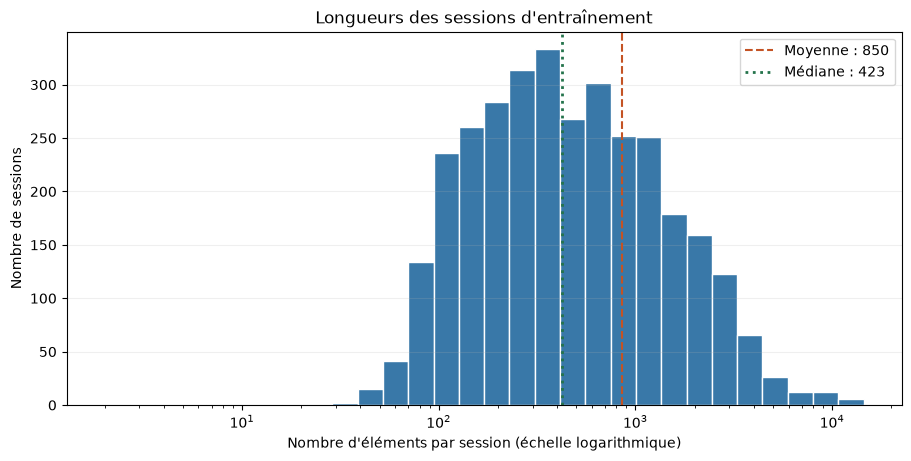

95 % des sessions ont au plus 2900 éléments ; maximum : 14468.


In [132]:
longueurs_train = sessions_train["sequence"].map(len)
longueurs_test = sessions_test["sequence"].map(len)
display(pd.DataFrame({"entraînement": longueurs_train.describe(), "test": longueurs_test.describe()}))

bornes = np.geomspace(longueurs_train.min(), longueurs_train.max() + 1, 31)
fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
ax.hist(longueurs_train, bins=bornes, color="#3978a8", edgecolor="white")
ax.set_xscale("log")
ax.axvline(longueurs_train.mean(), color="#c45324", linestyle="--", label=f"Moyenne : {longueurs_train.mean():.0f}")
ax.axvline(longueurs_train.median(), color="#24734b", linestyle=":", linewidth=2,
           label=f"Médiane : {longueurs_train.median():.0f}")
ax.set(title="Longueurs des sessions d'entraînement",
       xlabel="Nombre d'éléments par session (échelle logarithmique)", ylabel="Nombre de sessions")
ax.legend()
ax.grid(axis="y", alpha=0.2)
fig.savefig(DOSSIER_FIGURES / "01_longueurs_sessions.png", dpi=180)
plt.show()
print(f"95 % des sessions ont au plus {longueurs_train.quantile(0.95):.0f} éléments ; maximum : {longueurs_train.max()}.")

**Constat :** la moyenne est d'environ **850 éléments**, contre une médiane de **423**. Le 95e percentile est d'environ **2 900**, et le maximum atteint **14 468**. Quelques sessions très longues tirent la moyenne vers le haut. Les longueurs varient donc énormément d'une session à l'autre : pour comparer des sessions, il faudra raisonner en **proportions** plutôt qu'en comptages bruts.

### 3.4. Distribution de la variable dépendante Y

La variable à prédire est `utilisateur`. On examine le nombre de classes et le nombre de sessions par utilisateur. Le graphique classe les 247 utilisateurs par nombre décroissant de sessions.

Nombre d'utilisateurs distincts : 247


,nombre_sessions
count,247.000000
mean,13.275304
std,8.862380
min,4.000000
25%,7.000000
50%,12.000000
75%,16.000000
max,75.000000


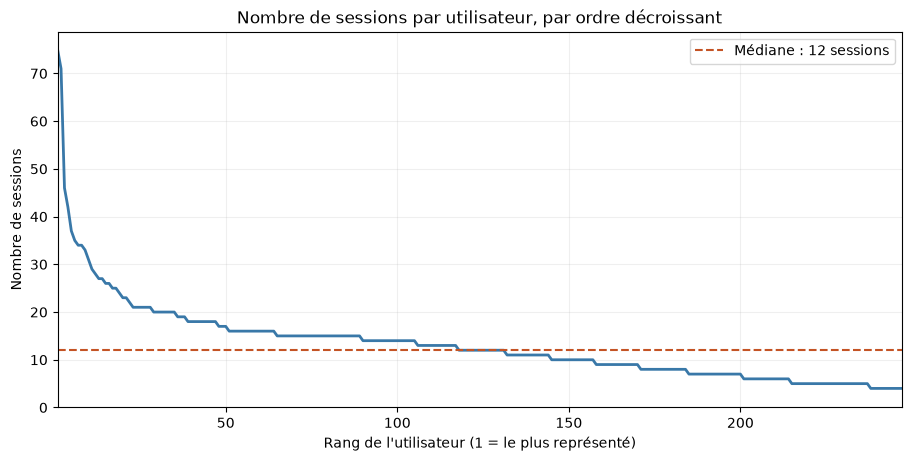

Les 10 utilisateurs les plus représentés regroupent 13.36% des sessions.
Rapport entre le plus grand et le plus petit effectif : 18.75.


In [133]:
def get_Y_stats(df):
    effectifs = df["utilisateur"].value_counts().rename("nombre_sessions")
    return effectifs.to_frame().assign(proportion=effectifs / len(df))


stats_Y = get_Y_stats(sessions_train)
print(f"Nombre d'utilisateurs distincts : {len(stats_Y)}")
display(stats_Y["nombre_sessions"].describe().to_frame())

effectifs_tries = stats_Y["nombre_sessions"]
fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
ax.plot(np.arange(1, len(effectifs_tries) + 1), effectifs_tries.to_numpy(), color="#3978a8", linewidth=2)
ax.axhline(effectifs_tries.median(), color="#c45324", linestyle="--",
           label=f"Médiane : {effectifs_tries.median():.0f} sessions")
ax.set(title="Nombre de sessions par utilisateur, par ordre décroissant",
       xlabel="Rang de l'utilisateur (1 = le plus représenté)", ylabel="Nombre de sessions",
       xlim=(1, len(effectifs_tries)), ylim=(0, effectifs_tries.max() * 1.05))
ax.legend()
ax.grid(alpha=0.2)
fig.savefig(DOSSIER_FIGURES / "02_effectifs_utilisateurs.png", dpi=180)
plt.show()

print(f"Les 10 utilisateurs les plus représentés regroupent {effectifs_tries.head(10).sum() / len(sessions_train):.2%} des sessions.")
print(f"Rapport entre le plus grand et le plus petit effectif : {effectifs_tries.max() / effectifs_tries.min():.2f}.")

**Constat :** la médiane est de **12 sessions par utilisateur**, avec un minimum de **4** et un maximum de **75**, soit un rapport de 1 à 19. Les dix utilisateurs les plus représentés regroupent **13,4 %** des sessions, contre 4 % avec une répartition uniforme.

**Conséquences :**

- **Les classes sont déséquilibrées.** Un modèle naïf favoriserait les gros utilisateurs ; c'est pourquoi on suit le F1 macro et on pondère les classes (`class_weight="balanced"`).
- **La validation croisée stratifiée est possible.** Chaque utilisateur a au moins 4 sessions, ce qui permet de conserver tous les utilisateurs dans chaque pli.

### 3.5. L'entraînement et le test se ressemblent-ils ?

Les ensembles ont des tailles différentes : on compare donc des proportions. Le premier panneau compare les navigateurs, le second la distribution cumulée des longueurs. Cette comparaison n'utilise que des données observables, sans étiquette du test.

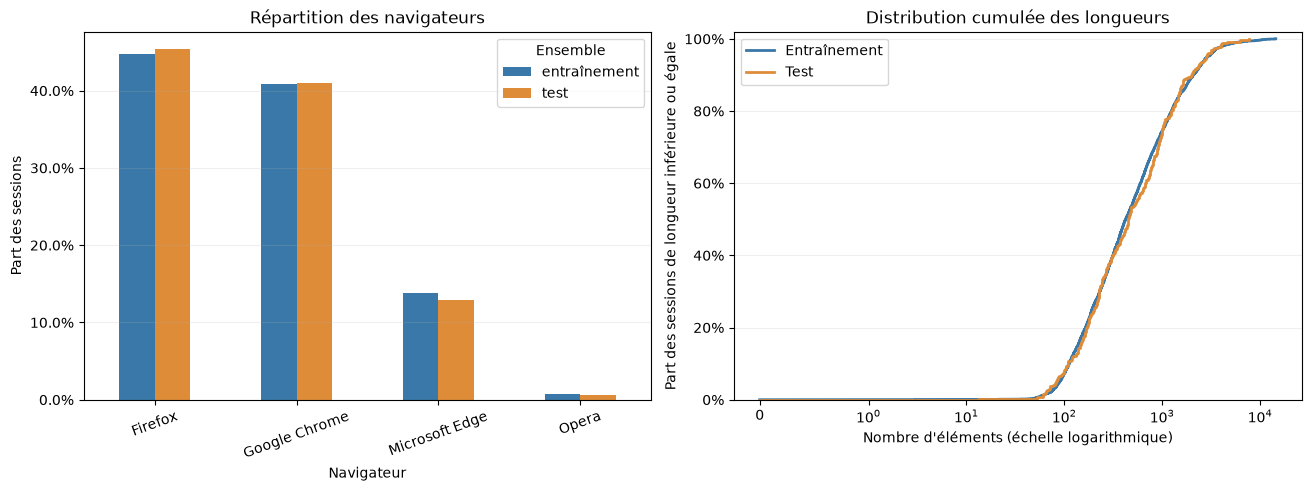

Écart maximal de proportion pour un navigateur : 0.79 points.
Médianes des longueurs : entraînement = 423 ; test = 450.


In [134]:
proportions_navigateurs = navigateurs.div(navigateurs.sum(axis=0), axis=1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), layout="constrained")
proportions_navigateurs.plot.bar(ax=axes[0], color=["#3978a8", "#df8c39"], rot=20)
axes[0].set(title="Répartition des navigateurs", xlabel="Navigateur", ylabel="Part des sessions")
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].legend(title="Ensemble")
for label, longueurs, couleur in [("Entraînement", longueurs_train, "#3978a8"), ("Test", longueurs_test, "#df8c39")]:
    valeurs, effectifs = np.unique(longueurs.to_numpy(), return_counts=True)
    axes[1].step(np.r_[0, valeurs], np.r_[0, effectifs.cumsum() / len(longueurs)], where="post",
                 label=label, color=couleur, linewidth=2)
axes[1].set_xscale("symlog", linthresh=1)
axes[1].set(title="Distribution cumulée des longueurs", xlabel="Nombre d'éléments (échelle logarithmique)",
            ylabel="Part des sessions de longueur inférieure ou égale", ylim=(0, 1.02))
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].legend()
for ax in axes:
    ax.grid(axis="y", alpha=0.2)
fig.savefig(DOSSIER_FIGURES / "03_comparaison_train_test.png", dpi=180)
plt.show()

ecart = (proportions_navigateurs["entraînement"] - proportions_navigateurs["test"]).abs().max()
print(f"Écart maximal de proportion pour un navigateur : {100 * ecart:.2f} points.")
print(f"Médianes des longueurs : entraînement = {longueurs_train.median():.0f} ; test = {longueurs_test.median():.0f}.")

**Constat :** l'écart maximal de part d'un navigateur entre les deux ensembles est de **0,79 point**. Les longueurs médianes sont de **423 éléments** dans l'entraînement et **450** dans le test, et les courbes cumulées sont proches. Le test semble donc représentatif de l'entraînement sur ces deux aspects, sans que cela garantisse l'absence d'autres différences.

### 3.6. Que contient une action ? Types, écrans, configurations et chaînes

On sépare chaque action en ses composants à l'aide des expressions régulières fournies dans les indications :

- le **type** est le texte avant le premier délimiteur, sans le suffixe `1` ;
- l'**écran**, la **configuration** et la **chaîne** sont les textes entre `( )`, `< >` et `$ $`.

Un élément n'est un marqueur temporel que s'il est entièrement de la forme `t` suivi de chiffres.

Pour chaque famille, on compte :

- les valeurs distinctes ;
- la part des actions qui portent la famille ;
- surtout, le nombre de valeurs **propres à un seul utilisateur**. Une valeur partagée par tous ne distingue personne, alors qu'une valeur rare est une véritable signature.

In [135]:
pattern_temps = re.compile(r"t\d+")
motif_type = re.compile(r"[(<$]")  # le type s'arrête au premier délimiteur
motif_ecran = re.compile(r"\((.*?)\)")
motif_configuration = re.compile(r"<(.*?)>")
motif_chaine = re.compile(r"\$(.*?)\$")
MOTIFS_CONTEXTE = {"ecran": motif_ecran, "conf": motif_configuration, "chaine": motif_chaine}


def est_temps(element):
    return pattern_temps.fullmatch(element) is not None


def type_action(action):
    return motif_type.split(action)[0].removesuffix("1")


utilisateurs_par_valeur = {famille: defaultdict(set) for famille in ["type", *MOTIFS_CONTEXTE]}
actions_portant = Counter()
nombre_actions_total = 0
for utilisateur, sequence in zip(sessions_train["utilisateur"], sessions_train["sequence"]):
    for element in sequence:
        if est_temps(element):
            continue
        nombre_actions_total += 1
        utilisateurs_par_valeur["type"][type_action(element)].add(utilisateur)
        for famille, motif in MOTIFS_CONTEXTE.items():
            valeurs = motif.findall(element)
            actions_portant[famille] += bool(valeurs)
            for valeur in valeurs:
                utilisateurs_par_valeur[famille][valeur].add(utilisateur)
actions_portant["type"] = nombre_actions_total

valeurs_test = {famille: set() for famille in utilisateurs_par_valeur}
for sequence in sessions_test["sequence"]:
    for element in sequence:
        if not est_temps(element):
            valeurs_test["type"].add(type_action(element))
            for famille, motif in MOTIFS_CONTEXTE.items():
                valeurs_test[famille].update(motif.findall(element))

noms_familles = {"type": "Types d'actions", "ecran": "Écrans", "conf": "Configurations", "chaine": "Chaînes"}
composantes = pd.DataFrame({
    noms_familles[famille]: {
        "valeurs distinctes (entraînement)": len(valeurs),
        "part des actions qui la portent": actions_portant[famille] / nombre_actions_total,
        "valeurs propres à un seul utilisateur": sum(len(u) == 1 for u in valeurs.values()),
        "valeurs utilisées par 200 utilisateurs ou plus": sum(len(u) >= 200 for u in valeurs.values()),
        "valeurs du test jamais vues": len(valeurs_test[famille] - set(valeurs)),
    }
    for famille, valeurs in utilisateurs_par_valeur.items()
}).T
print(f"{nombre_actions_total:,} actions dans l'entraînement (marqueurs temporels exclus).")
display(composantes.pipe(formater, {"part des actions qui la portent": "{:.1%}"}, precision=0))

2,270,247 actions dans l'entraînement (marqueurs temporels exclus).


,valeurs distinctes (entraînement),part des actions qui la portent,valeurs propres à un seul utilisateur,valeurs utilisées par 200 utilisateurs ou plus,valeurs du test jamais vues
Types d'actions,35,100.0%,0,19,0
Écrans,418,12.7%,147,9,8
Configurations,219,4.6%,41,3,2
Chaînes,76,15.9%,9,0,0


**Constat :** l'entraînement compte 2,27 millions d'actions. Les **35 types d'actions** sont partagés par presque tous les utilisateurs : 19 d'entre eux sont utilisés par au moins 200 des 247 utilisateurs, et aucun n'est propre à un seul. Les contextes, à l'inverse, sont nombreux et souvent personnels :

- **418 écrans**, dont **147 propres à un seul utilisateur** ;
- 219 configurations, dont 41 propres à un seul utilisateur ;
- 76 chaînes, dont 9 propres à un seul utilisateur.

Ces contextes sont peu fréquents dans les traces : un écran figure dans 12,7 % des actions, une configuration dans 4,6 % et une chaîne dans 15,9 %. Ce sont pourtant eux qui portent les signatures. Le test ne contient que 8 écrans et 2 configurations jamais vus à l'entraînement : le vocabulaire de l'entraînement couvre presque tout le test.

### 3.7. Contrôle de qualité des données brutes

On vérifie l'absence de valeurs manquantes (utilisateur, navigateur, champ vide) et on recherche les **traces identiques**, c'est-à-dire exactement la même suite d'éléments. Une trace répétée des deux côtés d'une séparation apprentissage / validation rendrait l'évaluation trop optimiste. Une même trace attribuée à plusieurs utilisateurs signalerait une ambiguïté.

In [136]:
def controler(sessions, avec_utilisateur):
    traces = Counter(tuple(sequence) for sequence in sessions["sequence"])
    utilisateurs_par_trace = defaultdict(set)
    if avec_utilisateur:
        for utilisateur, sequence in zip(sessions["utilisateur"], sessions["sequence"]):
            utilisateurs_par_trace[tuple(sequence)].add(utilisateur)
    ambigues = [trace for trace, utilisateurs in utilisateurs_par_trace.items() if len(utilisateurs) > 1]
    return pd.Series({
        "Utilisateur manquant": int((sessions["utilisateur"].str.strip() == "").sum()) if avec_utilisateur else pd.NA,
        "Navigateur manquant": int((sessions["navigateur"].str.strip() == "").sum()),
        "Sessions avec un champ vide": int(sessions["sequence"].map(lambda s: any(not e.strip() for e in s)).sum()),
        "Sessions sans aucune action": int(sessions["sequence"].map(lambda s: all(est_temps(e) for e in s)).sum()),
        "Traces répétées (copies en trop)": sum(n - 1 for n in traces.values()),
        "Traces attribuées à plusieurs utilisateurs": len(ambigues) if avec_utilisateur else pd.NA,
    }, dtype="Int64")


display(pd.DataFrame({"entraînement": controler(sessions_train, True), "test": controler(sessions_test, False)}))
traces_communes = set(map(tuple, sessions_train["sequence"])) & set(map(tuple, sessions_test["sequence"]))
print(f"Traces présentes à la fois dans l'entraînement et le test : {len(traces_communes)}")

,entraînement,test
Utilisateur manquant,0,<NA>
Navigateur manquant,0,0
Sessions avec un champ vide,0,0
Sessions sans aucune action,1,0
Traces répétées (copies en trop),0,0
Traces attribuées à plusieurs utilisateurs,0,<NA>


Traces présentes à la fois dans l'entraînement et le test : 0


**Constat :** aucune valeur manquante, aucun champ vide et aucune trace répétée. Une session d'entraînement ne contient aucune action (seulement des marqueurs temporels) : elle sera traitée en section 4.1. `<NA>` signifie « non applicable » (pas d'utilisateur dans le test).

## 4. Construction de caractéristiques

Un modèle de classification attend un **tableau** : une ligne par session et les mêmes colonnes numériques pour toutes les sessions. L'exploration conduit à deux représentations complémentaires :

| Représentation | Contenu | Pour quels modèles |
|---|---|---|
| **Tableau de variables** (section 4.3) | proportions de chaque type d'action, écran, configuration et chaîne ; rythme ; navigateur | forêts d'arbres et modèles classiques |
| **Documents TF-IDF** (section 4.5) | chaque session devient un texte dont les mots sont les actions complètes, leurs enchaînements et leurs composants | SVM linéaires |

### 4.1. Traitements préliminaires

On résume d'abord chaque session en une seule passe :

- **les comptages** des types, écrans, configurations et chaînes, ainsi que la proportion du suffixe `1` ;
- **le profil temporel :**
  - la durée, soit le dernier marqueur `tXX` ;
  - le nombre d'actions dans chaque fenêtre de 5 secondes, résumé par sa moyenne, son maximum (le pic) et son écart-type ;
  - le nombre d'actions par minute.

Ce résumé ne dépend que de la session elle-même : il n'apprend rien des autres sessions, et peut donc être calculé une fois pour toutes, sans fuite d'information.

In [137]:
def resumer_session(sequence):
    """Comptages et profil temporel d'une session (ne dépend que de la session elle-même)."""
    comptes = {"type": Counter(), "ecran": Counter(), "conf": Counter(), "chaine": Counter()}
    actions_par_fenetre = Counter()
    n_actions = n_suffixe_1 = 0
    temps_courant = 0
    for element in sequence:
        if est_temps(element):
            temps_courant = int(element[1:])
            continue
        n_actions += 1
        n_suffixe_1 += element.endswith("1")
        actions_par_fenetre[temps_courant] += 1
        comptes["type"][type_action(element)] += 1
        for famille, motif in MOTIFS_CONTEXTE.items():
            comptes[famille].update(motif.findall(element))
    fenetres = pd.Series(actions_par_fenetre, dtype=float)  # actions par fenêtre, dans l'ordre de la session
    return {
        "n_actions": n_actions,
        "n_suffixe_1": n_suffixe_1,
        "comptes": comptes,
        "duree_s": temps_courant,
        "actions_par_min": n_actions / (max(temps_courant, 5) / 60),
        "actions_par_fenetre_moy": fenetres.mean(),  # NaN si la session n'a aucune action
        "actions_par_fenetre_max": fenetres.max(),
        "actions_par_fenetre_std": fenetres.std(),   # NaN s'il n'y a qu'une fenêtre
    }


for tableau_sessions in [sessions_train, sessions_test]:
    tableau_sessions["resume"] = tableau_sessions["sequence"].map(resumer_session)
    tableau_sessions["n_actions"] = tableau_sessions["resume"].map(lambda r: r["n_actions"])

profil_temporel = pd.DataFrame([
    {cle: r[cle] for cle in ["n_actions", "duree_s", "actions_par_min", "actions_par_fenetre_max"]}
    for r in sessions_train["resume"]
], index=sessions_train.index)
display(profil_temporel.describe().T)

,count,mean,std,min,25%,50%,75%,max
n_actions,3279.0,692.359561,1005.873878,0.0,153.0,340.00,818.500000,11977.0
duree_s,3279.0,751.530955,1006.277841,5.0,185.0,395.00,945.000000,11790.0
actions_par_min,3279.0,56.284443,23.301728,0.0,44.0,52.85,63.969459,556.0
actions_par_fenetre_max,3278.0,32.466748,49.749841,1.0,17.0,25.00,38.000000,1859.0


**Sessions vides ou très courtes.** Une session de quelques actions ne contient presque aucune information sur son utilisateur. On liste les sessions de 5 actions ou moins dans l'entraînement et dans le test.

In [138]:
SEUIL_SESSIONS_COURTES = 5
tres_courtes = sessions_train[sessions_train["n_actions"] <= SEUIL_SESSIONS_COURTES]
display(tres_courtes.assign(
    sessions_de_l_utilisateur=tres_courtes["utilisateur"].map(stats_Y["nombre_sessions"]),
    elements=tres_courtes["sequence"].map(lambda s: " | ".join(s[:6])),
)[["utilisateur", "navigateur", "n_actions", "sessions_de_l_utilisateur", "elements"]])
print(f"Sessions de test de {SEUIL_SESSIONS_COURTES} actions ou moins : "
      f"{(sessions_test['n_actions'] <= SEUIL_SESSIONS_COURTES).sum()}")

,utilisateur,navigateur,n_actions,sessions_de_l_utilisateur,elements
1251,fvc,Google Chrome,0,29,t5 | t10 | t15
2684,zus,Firefox,2,13,Création d'un écran(infologic.core.accueil.Acc...
3141,fou,Google Chrome,1,21,Création d'un écran(infologic.core.accueil.Acc...


Sessions de test de 5 actions ou moins : 0


**Rafales : accident ou habitude ?** Certaines sessions présentent des pics de centaines d'actions en 5 secondes. On compare le pic de chaque session au pic habituel (médian) de son utilisateur. Un pic isolé chez un utilisateur ordinaire évoque un traitement automatique ; un pic récurrent est une habitude, donc une signature à conserver.

In [139]:
pics = profil_temporel.assign(utilisateur=sessions_train["utilisateur"])
pics["pic_median_utilisateur"] = pics.groupby("utilisateur")["actions_par_fenetre_max"].transform("median")
display(pics.sort_values("actions_par_fenetre_max", ascending=False).head(8)[
    ["utilisateur", "n_actions", "actions_par_fenetre_max", "pic_median_utilisateur"]])
print(f"99e percentile du pic sur 5 s : {pics['actions_par_fenetre_max'].quantile(0.99):.0f} actions")

,utilisateur,n_actions,actions_par_fenetre_max,pic_median_utilisateur
1806,opp,6761,1859.0,28.0
2971,vzc,4083,1226.0,38.5
694,flj,3025,1008.0,16.0
2770,oec,4769,403.0,26.0
234,oec,2854,331.0,26.0
628,kbf,4027,315.0,27.0
2814,fxg,8476,294.0,261.0
1616,cxt,765,291.0,23.0


99e percentile du pic sur 5 s : 140 actions


**Décisions de traitement :**

| Problème | Traitement | Justification |
|---|---|---|
| Sessions de 5 actions ou moins dans l'entraînement | **retirées de l'entraînement** | elles n'apportent aucune information, leurs utilisateurs gardent de nombreuses autres sessions, et le test n'en contient pas |
| Rafales et vitesses extrêmes | **plafonnées** au 99e percentile de l'entraînement, puis passage au logarithme | ce ne sont pas des erreurs de saisie ; on limite seulement leur influence sans supprimer de session, car certains utilisateurs n'en ont que 4 |
| Volumes et durées très asymétriques | **passage au logarithme** (`log1p`) | la forme normale des données, pas des valeurs aberrantes à supprimer |
| Valeurs du test jamais vues à l'entraînement | **ignorées** | le vocabulaire des colonnes est appris sur l'entraînement uniquement |

Le test n'est jamais filtré : ses 324 sessions reçoivent toutes une prédiction.

In [140]:
sessions = sessions_train[sessions_train["n_actions"] > SEUIL_SESSIONS_COURTES].copy()
print(f"Sessions retirées : {len(sessions_train) - len(sessions)}")
print(f"Sessions étiquetées conservées : {len(sessions)}, {sessions['utilisateur'].nunique()} utilisateurs")
print(f"Effectif minimal par utilisateur après retrait : {sessions['utilisateur'].value_counts().min()} sessions")

Sessions retirées : 3
Sessions étiquetées conservées : 3276, 247 utilisateurs
Effectif minimal par utilisateur après retrait : 4 sessions


### 4.2. Variable de classe

Comme dans les indications, `pd.Categorical` convertit l'identifiant de l'utilisateur en code numérique. Ces codes sont des identifiants de classes : on ne les utilise jamais comme des nombres à ordonner. La correspondance code → utilisateur est conservée, pour décoder les prédictions au moment de la soumission.

In [141]:
cible = pd.Categorical(sessions["utilisateur"])
y = pd.Series(cible.codes.astype(int), index=sessions.index, name="classe")
correspondance_classes = pd.Series(cible.categories, name="utilisateur")
classes = np.arange(len(correspondance_classes))
display(correspondance_classes.head(5).rename_axis("code").to_frame())
print(f"{len(classes)} classes, codées de 0 à {classes[-1]}.")

,utilisateur
code,
0,aho
1,ajo
2,akx
3,ald
4,ats


247 classes, codées de 0 à 246.


### 4.3. Obtention des caractéristiques : le tableau de variables

L'exploration montre que les utilisateurs se distinguent par **ce qu'ils font** (types d'actions), **où ils le font** (écrans, configurations, chaînes) et **à quel rythme**. Chaque session devient donc un vecteur de variables :

| Famille | Variables | Pourquoi |
|---|---|---|
| Navigateur | one-hot, une colonne par navigateur | chaque utilisateur utilise toujours le même (3.2) |
| Volume et temps | log du nombre d'actions, log de la durée, actions par minute (plafonnées), moyenne, log du pic (plafonné) et écart-type des actions par fenêtre de 5 s | le rythme diffère d'un utilisateur à l'autre |
| Types d'actions | **proportion** de chaque type | signatures de comportement |
| Suffixe `1` | proportion des actions qui le portent | sens non documenté, mais variable selon les utilisateurs |
| Chaînes | proportion de chaque chaîne, plus un indicateur « aucune chaîne » | l'absence de chaîne est elle-même une information |
| Écrans, configurations | proportion de chaque valeur | les valeurs rares sont des signatures (3.6) |

**Règles de construction :**

- **Proportions plutôt que comptages**, car les longueurs des sessions varient d'un facteur 1 000 (3.3).
- **Un vocabulaire appris sur l'entraînement seulement** : une valeur devient une colonne si elle apparaît dans **au moins 2 sessions**. Une valeur vue une seule fois ne permet pas d'apprendre. Les plafonds (99e percentiles) sont aussi appris sur l'entraînement.
- **Une construction encapsulée dans un transformateur scikit-learn** (`TableauVariables`). Ses étapes `fit` (apprendre le vocabulaire et les plafonds) et `transform` (construire les colonnes) sont refaites dans chaque pli de validation croisée, uniquement sur les sessions d'entraînement du pli. Le test reçoit exactement les mêmes colonnes, dans le même ordre, et ses valeurs inconnues sont ignorées.

In [142]:
FAMILLES_PROPORTIONS = ["type", "chaine", "ecran", "conf"]
COLONNES_ENTREE = ["navigateur", "resume"]


class TableauVariables(BaseEstimator, TransformerMixin):
    """Résumés de sessions -> tableau de variables numériques (vocabulaire et plafonds appris dans `fit`)."""

    def __init__(self, min_sessions=2, quantile_plafond=0.99):
        self.min_sessions = min_sessions
        self.quantile_plafond = quantile_plafond

    def fit(self, X, y=None):
        presence = {famille: Counter() for famille in FAMILLES_PROPORTIONS}
        for resume in X["resume"]:
            for famille in FAMILLES_PROPORTIONS:
                presence[famille].update(resume["comptes"][famille].keys())  # présence par session
        self.vocabulaire_ = {famille: sorted(v for v, n in presence[famille].items() if n >= self.min_sessions)
                             for famille in FAMILLES_PROPORTIONS}
        self.navigateurs_ = sorted(X["navigateur"].unique())
        self.plafond_pic_ = pd.Series([r["actions_par_fenetre_max"] for r in X["resume"]]).quantile(self.quantile_plafond)
        self.plafond_actions_par_min_ = pd.Series([r["actions_par_min"] for r in X["resume"]]).quantile(self.quantile_plafond)
        self.colonnes_ = (
            [f"nav_{n}" for n in self.navigateurs_]
            + ["log_nb_actions", "log_duree_s", "actions_par_min", "actions_par_fenetre_moy",
               "log_actions_par_fenetre_max", "actions_par_fenetre_std"]
            + [f"{famille}_{valeur}" for famille in FAMILLES_PROPORTIONS for valeur in self.vocabulaire_[famille]]
            + ["prop_suffixe_1", "aucune_chaine"]
        )
        return self

    def _variables(self, navigateur, resume):
        n = max(resume["n_actions"], 1)  # évite la division par 0
        v = {f"nav_{nav}": float(navigateur == nav) for nav in self.navigateurs_}
        v["log_nb_actions"] = np.log1p(resume["n_actions"])
        v["log_duree_s"] = np.log1p(resume["duree_s"])
        v["actions_par_min"] = min(resume["actions_par_min"], self.plafond_actions_par_min_)
        v["actions_par_fenetre_moy"] = resume["actions_par_fenetre_moy"]
        v["log_actions_par_fenetre_max"] = np.log1p(min(resume["actions_par_fenetre_max"], self.plafond_pic_))
        v["actions_par_fenetre_std"] = resume["actions_par_fenetre_std"]
        for famille in FAMILLES_PROPORTIONS:
            comptes = resume["comptes"][famille]
            for valeur in self.vocabulaire_[famille]:
                v[f"{famille}_{valeur}"] = comptes[valeur] / n
        v["prop_suffixe_1"] = resume["n_suffixe_1"] / n
        v["aucune_chaine"] = float(sum(resume["comptes"]["chaine"].values()) == 0)
        return v

    def transform(self, X):
        lignes = [self._variables(nav, resume) for nav, resume in zip(X["navigateur"], X["resume"])]
        # Écart-type non calculable (une seule fenêtre de 5 s) -> 0
        return pd.DataFrame(lignes, index=X.index, columns=self.colonnes_).fillna(0.0)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.colonnes_, dtype=object)


def famille_variable(colonne):
    prefixe = colonne.split("_", 1)[0]
    return {"nav": "navigateur", "type": "types d'actions", "chaine": "chaînes", "ecran": "écrans",
            "conf": "configurations"}.get(prefixe, "volume, temps et autres")


# À titre descriptif (sections 4 et 5) : tableau construit sur toutes les sessions étiquetées.
# Les modèles de la partie 6 réapprennent ce vocabulaire dans chaque pli, sur l'entraînement seulement.
tableau_descriptif = TableauVariables().fit(sessions[COLONNES_ENTREE])
X_variables = tableau_descriptif.transform(sessions[COLONNES_ENTREE])
X_variables_test = tableau_descriptif.transform(sessions_test[COLONNES_ENTREE])
print(f"Entraînement : {X_variables.shape[0]} sessions × {X_variables.shape[1]} variables")
print(f"Test : {X_variables_test.shape[0]} sessions × {X_variables_test.shape[1]} variables")
display(pd.Series(tableau_descriptif.colonnes_).map(famille_variable).value_counts()
        .rename("colonnes").rename_axis("famille").to_frame())

Entraînement : 3276 sessions × 616 variables
Test : 324 sessions × 616 variables


,colonnes
famille,
écrans,303
configurations,198
chaînes,68
types d'actions,35
"volume, temps et autres",8
navigateur,4


**Vérifications.** Le tableau du test doit avoir les mêmes colonnes, dans le même ordre, que celui de l'entraînement. On vérifie aussi l'absence de valeurs manquantes ou infinies, et que les proportions des types d'actions somment à 1.

In [143]:
assert list(X_variables.columns) == list(X_variables_test.columns)
assert len(X_variables_test) == len(sessions_test)
for tableau in [X_variables, X_variables_test]:
    assert not tableau.isna().any().any()
    assert np.isfinite(tableau.to_numpy()).all()
somme_types = X_variables.filter(regex="^type_").sum(axis=1)
print(f"Somme des proportions de types : de {somme_types.min():.3f} à {somme_types.max():.3f}.")
print(f"Colonnes constantes dans l'entraînement : {(X_variables.nunique() <= 1).sum()}")
print("Vérifications passées.")

Somme des proportions de types : de 1.000 à 1.000.
Colonnes constantes dans l'entraînement : 0
Vérifications passées.


### 4.4. Traitement des chaînes de caractères

Les informations textuelles sont toutes converties en nombres :

- **Le navigateur** (4 valeurs) est encodé en **one-hot** (`nav_…`). Un code entier imposerait un ordre artificiel entre les navigateurs ; les arbres s'en accommoderaient, mais pas les modèles linéaires.
- **Les écrans, configurations et chaînes** ne sont pas réduits à leur valeur dominante encodée en one-hot. Une session en utilise souvent plusieurs, et les plus discriminants sont rares, donc rarement dominants. On garde la **proportion de chaque valeur**, ce qui revient à un one-hot pondéré par la fréquence.
- **La cible** est encodée par `pd.Categorical` (4.2).

On vérifie que chaque session a exactement un navigateur encodé.

In [144]:
colonnes_navigateur = [c for c in X_variables.columns if c.startswith("nav_")]
assert (X_variables[colonnes_navigateur].sum(axis=1) == 1).all()
display(X_variables[colonnes_navigateur].sum().rename("sessions").to_frame())

,sessions
nav_Firefox,1465.0
nav_Google Chrome,1337.0
nav_Microsoft Edge,451.0
nav_Opera,23.0


### 4.5. Les sessions comme documents (TF-IDF)

Le tableau de variables **résume** chaque session, et ce résumé perd trois informations :

- **les combinaisons exactes** : `Exécution d'un bouton<DEF_03/24>$JCP$` est découpé en un type, une configuration et une chaîne, et le lien entre eux disparaît ;
- **l'ordre des actions** ;
- **les valeurs vues une seule fois**, exclues du vocabulaire.

On traite donc aussi chaque session comme un **document**. Ses « mots » sont :

- **le navigateur** (`NAV=…`) ;
- **chaque action complète**, telle qu'elle apparaît dans le fichier ;
- **chaque paire d'actions consécutives** (`action_1 >> action_2`), qui capte l'ordre et les habitudes de navigation ;
- **les composants séparés de chaque action** (`TYPE=`, `ECRAN=`, `CONF=`, `CHAINE=`), pour que deux actions sur le même écran se ressemblent.

Deux variantes de documents sont construites :

- **sans temps** : les marqueurs `tXX` sont retirés ;
- **avec temps** : chaque marqueur devient le mot `TEMPS`, gardé à sa place, et les marqueurs consécutifs sont fusionnés. Les paires « action >> TEMPS » indiquent alors les actions suivies d'un passage de 5 secondes, c'est-à-dire le **rythme** de l'utilisateur.

**Pondération TF-IDF.** Chaque document devient un vecteur, avec une colonne par mot du vocabulaire. Le poids d'un mot dans une session est le produit de deux termes :

- **TF**, sa fréquence dans la session. Avec `sublinear_tf=True`, on prend $1 + \ln(\text{occurrences})$ : un écran ouvert 100 fois ne pèse pas 100 fois plus qu'un écran ouvert une fois.
- **IDF**, sa rareté dans l'ensemble des sessions : $\ln\frac{1 + n}{1 + \text{df}} + 1$, où $n$ est le nombre de sessions et df le nombre de sessions qui contiennent le mot. Un mot présent partout pèse peu ; un mot rare est une signature.

Chaque vecteur est ensuite normalisé (norme euclidienne égale à 1) : on compare des profils, pas des volumes. Le vocabulaire et les IDF sont appris **dans le pipeline**, sur les seules sessions d'entraînement de chaque pli.

In [145]:
def construire_document(navigateur, sequence, avec_temps):
    """[NAV=navigateur, élément_1, élément_2, ...] ; avec_temps : chaque série de marqueurs devient « TEMPS »."""
    document = [f"NAV={navigateur}"]
    for element in sequence:
        if not est_temps(element):
            document.append(element)
        elif avec_temps and document[-1] != "TEMPS":
            document.append("TEMPS")
    return document


def mots_session(document):
    """Mots d'une session : navigateur, actions complètes, paires d'actions consécutives et composants."""
    navigateur, actions = document[0], document[1:]
    mots = [navigateur, *actions]
    mots += [f"{a} >> {b}" for a, b in zip(actions, actions[1:])]
    for action in actions:
        if action == "TEMPS":
            continue
        mots.append("TYPE=" + motif_type.split(action)[0])
        mots += ["ECRAN=" + valeur for valeur in motif_ecran.findall(action)]
        mots += ["CONF=" + valeur for valeur in motif_configuration.findall(action)]
        mots += ["CHAINE=" + valeur for valeur in motif_chaine.findall(action)]
    return mots


documents = {
    avec_temps: [construire_document(n, s, avec_temps) for n, s in zip(sessions["navigateur"], sessions["sequence"])]
    for avec_temps in [False, True]
}
documents_test = {
    avec_temps: [construire_document(n, s, avec_temps)
                 for n, s in zip(sessions_test["navigateur"], sessions_test["sequence"])]
    for avec_temps in [False, True]
}

exemple = mots_session(documents[True][0])
print(f"La première session donne {len(exemple)} mots. Exemples :")
for prefixe in ["NAV=", "TYPE=", "ECRAN=", "CONF=", "CHAINE="]:
    print("  ", next((m for m in exemple if m.startswith(prefixe)), f"(aucun mot {prefixe})"))
print("  ", next(m for m in exemple if " >> " in m and "TEMPS" not in m))
print("  ", next((m for m in exemple if " >> TEMPS" in m), "(aucune paire avec TEMPS)"))

La première session donne 9867 mots. Exemples :
   NAV=Firefox
   TYPE=Création d'un écran
   ECRAN=infologic.core.accueil.AccueilController
   CONF=DEF_03/24
   CHAINE=JCP
   Création d'un écran(infologic.core.accueil.AccueilController) >> Affichage d'une dialogue
   Création d'un écran(infologic.core.gui.controllers.nested.InputFormNestedWindow) >> TEMPS


**Taille du vocabulaire.** On compte, à titre descriptif, les mots distincts de chaque sorte dans les documents d'entraînement avec temps.

In [146]:
def sorte_mot(mot):
    if " >> " in mot:
        return "paire contenant TEMPS" if "TEMPS" in mot else "paire d'actions"
    for prefixe in ["NAV", "TYPE", "ECRAN", "CONF", "CHAINE"]:
        if mot.startswith(prefixe + "="):
            return f"composant {prefixe}"
    return "mot TEMPS" if mot == "TEMPS" else "action complète"


vocabulaire_descriptif = set()
for document in documents[True]:
    vocabulaire_descriptif.update(mots_session(document))
display(pd.Series(Counter(map(sorte_mot, vocabulaire_descriptif))).sort_values(ascending=False)
        .rename("mots distincts").to_frame())
print(f"Total : {len(vocabulaire_descriptif):,} mots distincts")
del vocabulaire_descriptif

,mots distincts
paire d'actions,64184
paire contenant TEMPS,9995
action complète,7086
composant ECRAN,418
composant CONF,219
composant CHAINE,76
composant TYPE,65
composant NAV,4
mot TEMPS,1


Total : 82,048 mots distincts


**Constat :** les documents avec temps des 3 276 sessions comptent **82 048 mots distincts**. Les paires d'actions consécutives en forment l'essentiel (64 184, plus 9 995 paires contenant `TEMPS`), devant les 7 086 actions complètes. Les composants n'ajoutent que quelques centaines de mots, mais chacun est présent dans de nombreuses sessions, et ils rapprochent des actions différentes sur le même écran. On compte 65 valeurs de `TYPE=` pour 35 types : dans les documents, le suffixe `1` n'est pas retiré, et il crée des variantes. Ce vocabulaire est plus de 130 fois plus large que le tableau de variables (616 colonnes).

**Augmentation de données.** Un utilisateur à 4 sessions n'a que 3 sessions d'entraînement dans un pli de validation croisée, et la section 7 montrera que les erreurs se concentrent sur les sessions courtes. Pour certains SVM, on ajoute donc à chaque session d'entraînement quelques **extraits contigus** tirés au hasard, par exemple 8 extraits de 30 à 200 éléments. Ce sont autant de « sessions courtes » supplémentaires du même utilisateur.

L'augmentation n'est appliquée qu'aux sessions d'**entraînement**, jamais aux sessions évaluées. Les sessions de moins de 60 éléments ne sont pas découpées.

In [147]:
def fenetres(document, rng, n=8, long_min=30, long_max=200):
    """`n` extraits contigus de `long_min` à `long_max` éléments d'une session (navigateur gardé en tête)."""
    navigateur, sequence = document[0], document[1:]
    if len(sequence) < 2 * long_min:
        return []
    extraits = []
    for _ in range(n):
        longueur = rng.integers(long_min, min(long_max, len(sequence) - 1) + 1)
        debut = rng.integers(0, len(sequence) - longueur + 1)
        extraits.append([navigateur] + sequence[debut:debut + longueur])
    return extraits


def augmenter(documents_entrainement, etiquettes, rng, **options):
    """Documents d'origine suivis de leurs extraits, avec la même étiquette."""
    documents_augmentes, etiquettes_augmentees = [], []
    for document, etiquette in zip(documents_entrainement, etiquettes):
        documents_augmentes.append(document)
        etiquettes_augmentees.append(etiquette)
        for extrait in fenetres(document, rng, **options):
            documents_augmentes.append(extrait)
            etiquettes_augmentees.append(etiquette)
    return documents_augmentes, etiquettes_augmentees


EXTRAITS_8 = dict(n=8, long_min=30, long_max=200)
EXTRAITS_15 = dict(n=15, long_min=20, long_max=150)
docs_exemple, _ = augmenter(documents[True][:20], list(y.iloc[:20]), np.random.default_rng(0), **EXTRAITS_8)
print(f"20 sessions deviennent {len(docs_exemple)} documents avec 8 extraits de 30 à 200 éléments.")

20 sessions deviennent 180 documents avec 8 extraits de 30 à 200 éléments.


## 5. Statistiques simples sur les variables

### 5.1. Inspection des caractéristiques

Le tableau suivant décrit les variables de volume et de temps. Pour les proportions, on indique plutôt, par famille, la part de valeurs nulles : le tableau est très **creux**, car une session n'utilise qu'une petite partie des écrans et configurations.

In [148]:
colonnes_volume = [c for c in X_variables.columns if famille_variable(c) == "volume, temps et autres"]
display(X_variables[colonnes_volume].describe().T)

familles = pd.Series(X_variables.columns, index=X_variables.columns).map(famille_variable)
creux = pd.DataFrame({
    "colonnes": familles.value_counts(),
    "part de valeurs nulles": (X_variables == 0).mean().groupby(familles).mean(),
}).sort_values("colonnes", ascending=False)
display(creux.pipe(formater, {"part de valeurs nulles": "{:.1%}"}))

,count,mean,std,min,25%,50%,75%,max
log_nb_actions,3276.0,5.914227,1.101469,2.639057,5.036953,5.834811,6.709304,9.390827
log_duree_s,3276.0,6.034070,1.083326,2.397895,5.225747,5.981414,6.853560,9.375092
actions_par_min,3276.0,55.801912,18.676725,15.073892,44.000000,52.882804,63.977444,133.514778
actions_par_fenetre_moy,3276.0,4.586476,1.726366,1.250000,3.599045,4.350000,5.238757,34.750000
log_actions_par_fenetre_max,3276.0,3.276462,0.580402,1.386294,2.890372,3.258097,3.663562,4.948760
actions_par_fenetre_std,3276.0,5.096353,3.907198,0.596583,3.423677,4.499287,5.843954,116.422962
prop_suffixe_1,3276.0,0.155453,0.187737,0.000000,0.010983,0.090909,0.224527,0.907975
aucune_chaine,3276.0,0.319902,0.466510,0.000000,0.000000,0.000000,1.000000,1.000000


,colonnes,part de valeurs nulles
écrans,303,96.5%
configurations,198,97.5%
chaînes,68,96.7%
types d'actions,35,51.4%
"volume, temps et autres",8,11.2%
navigateur,4,75.0%


**Constat :** après passage au logarithme, le nombre d'actions et la durée ont des distributions resserrées (écart-type d'environ 1,1). Le plafonnement agit bien :

- le rythme `actions_par_min` est limité à 134 actions par minute, pour une médiane de 53 ;
- le log du pic plafonne à 4,9, soit environ 140 actions en 5 secondes.

L'écart-type par fenêtre n'est pas plafonné : son maximum (116) reste extrême. Une session sur trois (32 %) n'utilise aucune chaîne, et la part médiane du suffixe `1` est de 9 %.

Le tableau est très **creux** : 96,5 % des valeurs des écrans sont nulles, comme 97,5 % des configurations et 96,7 % des chaînes. Même pour les types d'actions, une valeur sur deux est nulle. On verra en 6.5 que les modèles fondés sur une distance entre sessions (KNN, SVC à noyau RBF) en souffrent.

### 5.2. Inspection d'une caractéristique pour une classe particulière

On choisit quatre utilisateurs de manière reproductible parmi ceux qui ont au moins dix sessions, à des rangs régulièrement espacés dans la distribution des effectifs. On compare trois caractéristiques de familles différentes : le rythme, la part d'un type d'action et la part du suffixe `1`. Chaque boîte montre la médiane et les quartiles, et les points représentent toutes les sessions de l'utilisateur.

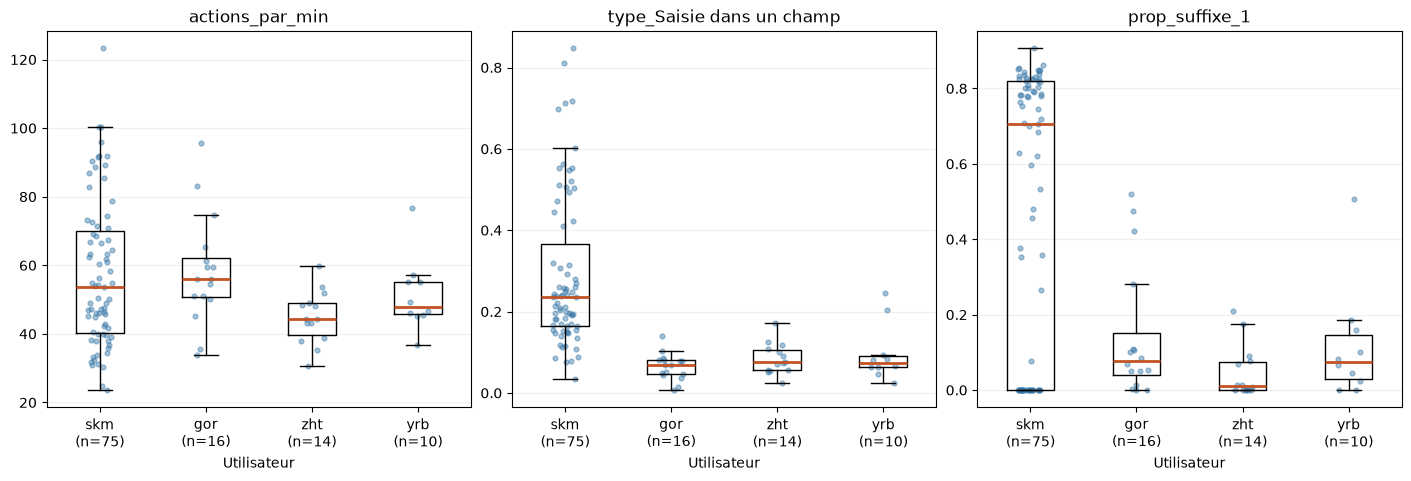

,actions_par_min,type_Saisie dans un champ,prop_suffixe_1
utilisateur,,,
skm,53.684211,0.234694,0.705503
gor,56.009494,0.068821,0.076800
zht,44.296703,0.074959,0.010767
yrb,47.920385,0.074457,0.075047


In [149]:
effectifs_eligibles = sessions["utilisateur"].value_counts()
effectifs_eligibles = effectifs_eligibles[effectifs_eligibles >= 10].sort_index().sort_values(ascending=False, kind="stable")
positions = np.linspace(0, len(effectifs_eligibles) - 1, min(4, len(effectifs_eligibles)), dtype=int)
utilisateurs_choisis = effectifs_eligibles.index[positions].tolist()
variables_comparees = [c for c in ["actions_par_min", "type_Saisie dans un champ", "prop_suffixe_1"] if c in X_variables]
fig, axes = plt.subplots(1, len(variables_comparees), figsize=(14, 4.7), layout="constrained")
rng_graphique = np.random.default_rng(GRAINE)
for ax, variable in zip(np.atleast_1d(axes), variables_comparees):
    groupes = [X_variables.loc[sessions["utilisateur"] == u, variable].to_numpy() for u in utilisateurs_choisis]
    ax.boxplot(groupes, tick_labels=[f"{u}\n(n={len(g)})" for u, g in zip(utilisateurs_choisis, groupes)],
               showfliers=False, medianprops={"color": "#c45324", "linewidth": 2})
    for position, groupe in enumerate(groupes, start=1):
        ax.scatter(position + rng_graphique.uniform(-0.12, 0.12, len(groupe)), groupe, s=12, color="#3978a8", alpha=0.45)
    ax.set(title=variable, xlabel="Utilisateur")
    ax.grid(axis="y", alpha=0.2)
fig.savefig(DOSSIER_FIGURES / "04_variables_par_utilisateur.png", dpi=180)
plt.show()
display(X_variables.loc[sessions["utilisateur"].isin(utilisateurs_choisis), variables_comparees]
        .groupby(sessions["utilisateur"]).median().reindex(utilisateurs_choisis))

**Constat :** les quatre utilisateurs ont des rythmes voisins : les médianes vont de 44 à 56 actions par minute, et les boîtes se recouvrent largement. Le rythme seul ne permet donc pas de les distinguer.

En revanche, `skm` se détache nettement sur les deux autres variables :

- la saisie dans un champ représente 23 % des actions de `skm` (médiane), contre environ 7 % pour les trois autres ;
- la part médiane du suffixe `1` est de 71 % chez `skm`, contre 8 % au plus chez les autres. Cette part est toutefois **bimodale** : une partie des sessions de `skm` n'en contient aucun.

Une variable peut donc distinguer certains utilisateurs, mais aucune ne les distingue tous : il faut en combiner beaucoup.

### 5.3. Quelles variables séparent le mieux les utilisateurs ?

Pour généraliser la comparaison précédente à toutes les variables et à tous les utilisateurs, on calcule le **rapport de corrélation η²**. C'est la part de la variance d'une variable expliquée par l'utilisateur :

$$\eta^2 = \frac{\sum_{u} n_u (\bar{x}_u - \bar{x})^2}{\sum_i (x_i - \bar{x})^2}$$

Si η² est proche de 1, la variable prend des valeurs très différentes d'un utilisateur à l'autre et très stables pour un même utilisateur : c'est une bonne signature. Avec 247 groupes, η² vaut environ 7 % même pour une variable sans aucun lien avec l'utilisateur. Seules les valeurs nettement supérieures sont donc informatives.

In [150]:
moyennes_globales = X_variables.mean()
variance_totale = ((X_variables - moyennes_globales) ** 2).sum()
variance_inter = ((X_variables.groupby(sessions["utilisateur"]).transform("mean") - moyennes_globales) ** 2).sum()
eta2 = (variance_inter / variance_totale.replace(0, np.nan)).dropna().sort_values(ascending=False)

print("Les 15 variables les plus liées à l'utilisateur :")
display(eta2.head(15).rename("η²").to_frame().pipe(formater, "{:.1%}"))
eta2_familles = eta2.groupby(eta2.index.map(famille_variable)).agg(["median", "max", "size"])
eta2_familles.columns = ["η² médian", "η² maximal", "colonnes"]
display(eta2_familles.sort_values("η² médian", ascending=False)
        .pipe(formater, {"η² médian": "{:.1%}", "η² maximal": "{:.1%}"}))

Les 15 variables les plus liées à l'utilisateur :


,η²
nav_Opera,100.0%
nav_Microsoft Edge,100.0%
nav_Google Chrome,100.0%
nav_Firefox,100.0%
type_Lancement d'un tableau de bord,96.7%
type_Sélection d'un flag,96.1%
type_Entrée en saisie dans un formulaire,96.1%
type_Désélection d'un flag,94.9%
type_Filtrage / Tri,94.6%
type_Clic sur une grille d'historique de recherche,91.8%


,η² médian,η² maximal,colonnes
navigateur,100.0%,100.0%,4
types d'actions,41.1%,96.7%,35
chaînes,29.5%,91.2%,68
"volume, temps et autres",28.9%,57.9%,8
configurations,14.1%,90.1%,198
écrans,12.0%,78.2%,303


**Constat :** le navigateur a un η² de **100 %**, ce qui traduit le constat de la section 3.2 : chaque utilisateur n'en utilise qu'un. Viennent ensuite des types d'actions (lancement d'un tableau de bord, 96,7 % ; sélection d'un flag, 96,1 %), la chaîne `TRACE` (91,2 %) et quelques configurations.

Par famille, les **types d'actions** sont les plus liés à l'utilisateur (η² médian de 41 %), devant les chaînes (30 %) et les variables de volume et de temps (29 %). Les écrans et les configurations ont un η² médian faible (12 % et 14 %), proche du niveau du hasard (environ 7 %), mais des maxima élevés : la plupart ne distinguent personne, et quelques-uns sont des signatures fortes. Un η² très élevé peut d'ailleurs venir d'une valeur utilisée par un ou deux utilisateurs seulement : il signale alors une signature, et non une variable utile pour tous.

### 5.4. Redondance entre caractéristiques

Une matrice de corrélation de **Spearman**, calculée sur les rangs, repère les relations monotones entre les variables de volume, de temps et quelques proportions. Les codes des utilisateurs n'y figurent jamais, car leur ordre est arbitraire. Une forte corrélation signale une redondance, mais ne mesure pas le pouvoir prédictif.

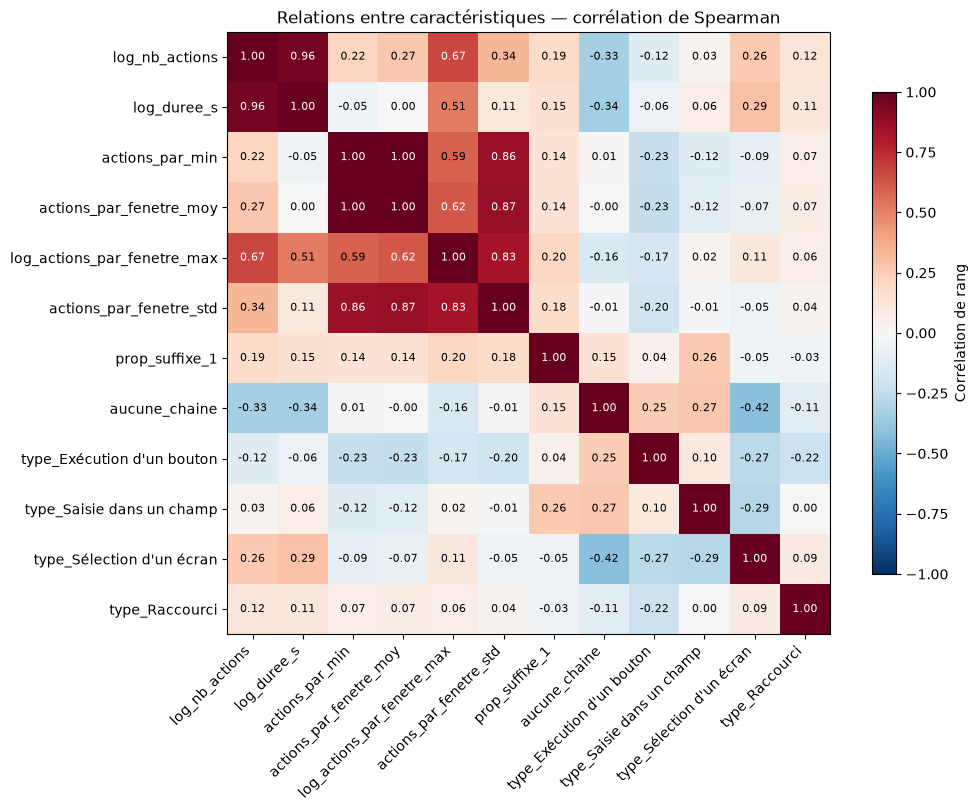

,variable_1,variable_2,rho
21,actions_par_min,actions_par_fenetre_moy,0.997871
0,log_nb_actions,log_duree_s,0.958802
31,actions_par_fenetre_moy,actions_par_fenetre_std,0.869001
23,actions_par_min,actions_par_fenetre_std,0.860735
38,log_actions_par_fenetre_max,actions_par_fenetre_std,0.830844
3,log_nb_actions,log_actions_par_fenetre_max,0.668816


In [151]:
candidates = ["log_nb_actions", "log_duree_s", "actions_par_min", "actions_par_fenetre_moy",
              "log_actions_par_fenetre_max", "actions_par_fenetre_std", "prop_suffixe_1", "aucune_chaine",
              "type_Exécution d'un bouton", "type_Saisie dans un champ", "type_Sélection d'un écran", "type_Raccourci"]
colonnes_correlation = [c for c in candidates if c in X_variables and X_variables[c].nunique() > 1]
correlations = X_variables[colonnes_correlation].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8), layout="constrained")
image = ax.imshow(correlations, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(colonnes_correlation)), colonnes_correlation, rotation=45, ha="right")
ax.set_yticks(range(len(colonnes_correlation)), colonnes_correlation)
for i in range(len(colonnes_correlation)):
    for j in range(len(colonnes_correlation)):
        valeur = correlations.iloc[i, j]
        ax.text(j, i, f"{valeur:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(valeur) > 0.6 else "black")
ax.set_title("Relations entre caractéristiques — corrélation de Spearman")
fig.colorbar(image, ax=ax, shrink=0.8, label="Corrélation de rang")
fig.savefig(DOSSIER_FIGURES / "05_correlations_variables.png", dpi=180)
plt.show()

paires = pd.DataFrame([{"variable_1": a, "variable_2": b, "rho": correlations.loc[a, b]}
                       for i, a in enumerate(colonnes_correlation) for b in colonnes_correlation[i + 1:]])
display(paires.loc[paires["rho"].abs().sort_values(ascending=False).index].head(6))

**Constat :** deux paires de variables sont presque redondantes :

- `actions_par_min` et `actions_par_fenetre_moy` (ρ = 0,998) mesurent presque la même chose : le nombre moyen d'actions par unité de temps ;
- le log du nombre d'actions et le log de la durée (ρ = 0,96) : une session longue en actions l'est aussi en temps.

Les mesures de rythme sont également liées à l'écart-type par fenêtre (ρ de 0,83 à 0,87). Cette redondance ne gêne pas les forêts, mais elle répartit l'importance entre variables corrélées (section 8.5). On conserve ces variables : elles ne représentent que 8 colonnes sur 616.

## 6. Développement d'une solution de classification automatique

**Démarche :**

1. **6.1** — on réserve 20 % des sessions étiquetées pour l'évaluation finale (partie 7). Elles ne servent à aucun choix.
2. **6.2** — sur les 80 % restants, chaque modèle est évalué par **validation croisée stratifiée à 3 plis**.
3. **6.3** — on décrit les matrices réellement données aux modèles.
4. **6.4** — on définit le protocole commun.
5. **6.5 et 6.6** — on entraîne les modèles, **une cellule par entraînement** :
   - les modèles classiques, sur le tableau de variables ;
   - les SVM linéaires, sur les documents TF-IDF.
6. **6.7** — on combine les meilleurs modèles à partir de leurs prédictions hors échantillon, sans nouvel entraînement.
7. **6.8** — on compare tous les résultats.

Pour chaque modèle, la validation croisée produit des **prédictions hors échantillon** : chaque session d'apprentissage est prédite par un modèle qui ne l'a pas vue. Ces prédictions donnent les scores (accuracy et F1 macro, moyenne et écart-type sur les 3 plis). Elles servent aussi d'entrées à la combinaison de la section 6.7, sans réentraîner les modèles.

### 6.1. Séparation de l'apprentissage et de la validation réservée (80/20)

La séparation est **stratifiée** par utilisateur : chaque utilisateur garde la même part de ses sessions de chaque côté. La graine est fixée pour la reproductibilité.

In [152]:
indices_apprentissage, indices_validation = train_test_split(
    np.arange(len(sessions)), test_size=0.2, stratify=y, random_state=GRAINE)
indices_apprentissage.sort()
indices_validation.sort()
variables_sessions = sessions[COLONNES_ENTREE]


def sous_ensemble(indices):
    """Les deux représentations, le navigateur, la longueur et la cible des sessions étiquetées `indices`."""
    indices = np.asarray(indices)
    return {
        "variables": variables_sessions.iloc[indices],
        "sans_temps": [documents[False][i] for i in indices],
        "avec_temps": [documents[True][i] for i in indices],
        "navigateur": sessions["navigateur"].to_numpy()[indices],
        "n_actions": sessions["n_actions"].to_numpy()[indices],
        "y": y.to_numpy()[indices],
    }


donnees_app = sous_ensemble(indices_apprentissage)
donnees_val = sous_ensemble(indices_validation)
y_app, y_val = donnees_app["y"], donnees_val["y"]
print(f"Apprentissage : {len(y_app)} sessions ; validation réservée : {len(y_val)} sessions")

Apprentissage : 2620 sessions ; validation réservée : 656 sessions


**Contrôle de la séparation.** On vérifie qu'aucune session n'est des deux côtés, que tous les utilisateurs sont présents dans l'apprentissage, et que la part de chaque utilisateur est conservée.

In [153]:
assert not set(indices_apprentissage) & set(indices_validation)
assert set(y_app) == set(classes)
parts = pd.DataFrame({
    "global": pd.Series(y).value_counts(normalize=True),
    "apprentissage": pd.Series(y_app).value_counts(normalize=True),
    "validation": pd.Series(y_val).value_counts(normalize=True),
}).fillna(0)
print(f"Utilisateurs présents en validation : {pd.Series(y_val).nunique()} sur {len(classes)}")
print(f"Écart maximal de part d'un utilisateur : {100 * (parts['apprentissage'] - parts['global']).abs().max():.3f} point "
      f"(apprentissage), {100 * (parts['validation'] - parts['global']).abs().max():.3f} point (validation)")
sessions_validation = pd.Series(y_val).value_counts()
print(f"Utilisateurs avec une seule session de validation : {(sessions_validation == 1).sum()} ; "
      f"avec deux : {(sessions_validation == 2).sum()}")
print(f"Effectif minimal d'un utilisateur dans l'apprentissage : {pd.Series(y_app).value_counts().min()} sessions")

Utilisateurs présents en validation : 247 sur 247
Écart maximal de part d'un utilisateur : 0.023 point (apprentissage), 0.090 point (validation)
Utilisateurs avec une seule session de validation : 63 ; avec deux : 68
Effectif minimal d'un utilisateur dans l'apprentissage : 3 sessions


**Constat :** les **2 620 sessions** d'apprentissage et les **656 sessions** réservées couvrent toutes les 247 utilisateurs. La stratification est fidèle : la part d'un utilisateur ne s'écarte jamais de plus de 0,09 point de sa part globale, et chaque utilisateur garde au moins 3 sessions d'apprentissage.

En revanche, **63 utilisateurs n'ont qu'une seule session de validation**, et 68 en ont deux. Pour eux, le F1 de la partie 7 reposera sur une ou deux prédictions : le F1 macro de validation sera donc bruité. C'est pourquoi les modèles sont choisis par validation croisée.

### 6.2. Plis de validation croisée dans l'apprentissage

Les 3 plis sont fixés **une fois pour toutes** : tous les modèles sont évalués sur exactement les mêmes découpages, et leurs prédictions hors échantillon peuvent donc être combinées (section 6.7). Avec 3 plis, chaque utilisateur, qui a au moins 3 sessions d'apprentissage, est présent dans chaque pli d'entraînement.

In [154]:
validation_croisee = StratifiedKFold(n_splits=3, shuffle=True, random_state=GRAINE)
plis = list(validation_croisee.split(np.zeros(len(y_app)), y_app))
display(pd.DataFrame([
    {"pli": k + 1, "sessions d'entraînement": len(entrainement), "sessions évaluées": len(evaluation),
     "utilisateurs dans l'entraînement": len(np.unique(y_app[entrainement]))}
    for k, (entrainement, evaluation) in enumerate(plis)
]).set_index("pli"))

,sessions d'entraînement,sessions évaluées,utilisateurs dans l'entraînement
pli,,,
1,1746,874,247
2,1747,873,247
3,1747,873,247


### 6.3. Des représentations aux matrices données aux modèles

On ajuste, sur l'apprentissage seul, la construction du tableau de variables et les deux vectoriseurs TF-IDF. On peut ainsi décrire les matrices obtenues. Dans les validations croisées, ces mêmes étapes seront réajustées dans chaque pli.

In [155]:
def creer_vectoriseur(use_idf=True):
    return TfidfVectorizer(analyzer=mots_session, sublinear_tf=True, lowercase=False, use_idf=use_idf)


tableau_app = TableauVariables().fit(donnees_app["variables"])
print(f"Tableau de variables appris sur l'apprentissage : {len(tableau_app.colonnes_)} colonnes")
display(pd.Series(tableau_app.colonnes_).map(famille_variable).value_counts().rename("colonnes").to_frame())

for representation in ["sans_temps", "avec_temps"]:
    vectoriseur = creer_vectoriseur().fit(donnees_app[representation])
    matrice = vectoriseur.transform(donnees_app[representation])
    print(f"TF-IDF {representation.replace('_', ' ')} : {matrice.shape[1]:,} mots, "
          f"{matrice.nnz / np.prod(matrice.shape):.2%} de valeurs non nulles")
del tableau_app, vectoriseur, matrice

Tableau de variables appris sur l'apprentissage : 589 colonnes


,colonnes
écrans,285
configurations,191
chaînes,66
types d'actions,35
"volume, temps et autres",8
navigateur,4


TF-IDF sans temps : 87,734 mots, 0.34% de valeurs non nulles
TF-IDF avec temps : 73,263 mots, 0.43% de valeurs non nulles


**Constat :** appris sur les 2 620 sessions d'apprentissage, le tableau compte **589 colonnes**, contre 616 sur toutes les sessions : une valeur vue dans moins de 2 sessions d'apprentissage ne devient pas une colonne.

Les documents donnent des matrices bien plus larges et très creuses :

- **87 734 mots** sans temps, dont 0,34 % de valeurs non nulles ;
- **73 263 mots** avec temps, dont 0,43 % de valeurs non nulles.

La variante avec temps compte moins de mots. Une explication : le mot `TEMPS` s'intercale dans une partie des paires d'actions, remplacées par des paires « action >> TEMPS », moins variées. Des matrices aussi larges et creuses conviennent aux SVM linéaires (6.6).

### 6.4. Protocole d'entraînement commun

La fonction `entrainer` applique le même protocole à tous les modèles :

1. Pour chaque réglage d'hyperparamètres proposé, elle entraîne un modèle neuf sur chaque pli d'entraînement. Si une augmentation est demandée, elle n'est appliquée qu'à ces sessions d'entraînement.
2. Elle prédit les sessions du pli évalué. On obtient une probabilité par utilisateur, ou un score de décision pour les SVM.
3. Elle calcule l'accuracy et le F1 macro de chaque pli, puis leur moyenne et leur écart-type.
4. Elle **retient le réglage de meilleur F1 macro**, la métrique du classement.

Les modèles sont libérés après chaque pli, car une forêt de 500 arbres sur 247 classes occupe plus d'un gigaoctet. Les avertissements de non-convergence sont comptés et affichés au lieu d'être masqués.

**Pondération des classes.** Les forêts et les SVM utilisent `class_weight="balanced"` : chaque utilisateur pèse autant dans l'apprentissage, quel que soit son nombre de sessions. C'est cohérent avec le F1 macro.

In [156]:
resultats_cv = {}       # nom du modèle -> scores du réglage retenu
scores_cv = {}          # nom du modèle -> prédictions hors échantillon du réglage retenu
scores_reglages = {}    # nom du modèle -> {réglage -> prédictions hors échantillon}
details_reglages = []   # une ligne par réglage testé


def selectionner(X, indices):
    return X.iloc[indices] if isinstance(X, pd.DataFrame) else [X[i] for i in indices]


def ajuster_pli(fabrique, X, y_cible, indices_entrainement, indices_evaluation, augmentation, numero_pli):
    """Entraîne un modèle neuf sur un pli et renvoie ses scores (probabilités ou décisions) sur le pli évalué."""
    X_entrainement, y_entrainement = selectionner(X, indices_entrainement), list(y_cible[indices_entrainement])
    if augmentation is not None:
        graine, options = augmentation
        X_entrainement, y_entrainement = augmenter(X_entrainement, y_entrainement,
                                                   np.random.default_rng([graine, numero_pli]), **options)
    with warnings.catch_warnings(record=True) as avertissements:
        warnings.simplefilter("always", ConvergenceWarning)
        modele = fabrique().fit(X_entrainement, y_entrainement)
    assert list(modele.classes_) == list(classes)
    X_evaluation = selectionner(X, indices_evaluation)
    scores = modele.predict_proba(X_evaluation) if hasattr(modele, "predict_proba") else modele.decision_function(X_evaluation)
    return indices_evaluation, scores, sum(issubclass(a.category, ConvergenceWarning) for a in avertissements)


def predictions_hors_echantillon(fabrique, X, augmentation=None, n_jobs=1):
    taches = Parallel(n_jobs=n_jobs)(
        delayed(ajuster_pli)(fabrique, X, y_app, entrainement, evaluation, augmentation, k)
        for k, (entrainement, evaluation) in enumerate(plis))
    scores = np.zeros((len(y_app), len(classes)))
    for indices_evaluation, scores_pli, _ in taches:
        scores[indices_evaluation] = scores_pli
    return scores, sum(n for *_, n in taches)


def mesurer(representation, reglage, scores, duree_s=np.nan, avertissements=0):
    """Accuracy et F1 macro de prédictions hors échantillon, pli par pli."""
    predictions = classes[np.asarray(scores).argmax(axis=1)]
    accuracy = [accuracy_score(y_app[ev], predictions[ev]) for _, ev in plis]
    f1 = [f1_score(y_app[ev], predictions[ev], average="macro") for _, ev in plis]
    return {"representation": representation, "reglage": reglage,
            "accuracy_cv": np.mean(accuracy), "std_accuracy_cv": np.std(accuracy),
            "f1_macro_cv": np.mean(f1), "std_f1_macro_cv": np.std(f1),
            "duree_s": duree_s, "avertissements_convergence": avertissements}


FORMAT_RESULTATS = {"accuracy_cv": "{:.2%}", "std_accuracy_cv": "{:.2%}", "f1_macro_cv": "{:.2%}",
                    "std_f1_macro_cv": "{:.2%}", "duree_s": "{:.0f}"}


def entrainer(nom, representation, reglages, augmentation=None, n_jobs=1):
    """Évalue chaque réglage par validation croisée et retient celui de meilleur F1 macro."""
    cle = "variables" if representation in ("aucune", "616 variables") else representation
    lignes = {}
    for reglage, fabrique in reglages.items():
        debut = time.perf_counter()
        scores, avertissements = predictions_hors_echantillon(fabrique, donnees_app[cle], augmentation, n_jobs)
        lignes[reglage] = mesurer(representation, reglage, scores, time.perf_counter() - debut, avertissements)
        scores_reglages.setdefault(nom, {})[reglage] = scores
        details_reglages.append({"modele": nom, **lignes[reglage]})
    tableau = pd.DataFrame(lignes).T
    retenu = tableau["f1_macro_cv"].astype(float).idxmax()
    resultats_cv[nom] = lignes[retenu]
    scores_cv[nom] = scores_reglages[nom][retenu]
    tableau["retenu"] = np.where(tableau.index == retenu, "✔", "")
    print(f"{nom} — {representation}")
    display(tableau.drop(columns=["representation", "reglage"]).pipe(formater, FORMAT_RESULTATS))


def sur_variables(modele, standardiser=False):
    """Pipeline : construction du tableau de variables (apprise sur le pli), standardisation éventuelle, modèle."""
    etapes = [("variables", TableauVariables())]
    if standardiser:
        etapes.append(("standardisation", StandardScaler()))
    return Pipeline(etapes + [("modele", modele)])


def creer_svm_tfidf(C=1.0, use_idf=True):
    """TF-IDF des mots de session + SVM linéaire à classes pondérées."""
    return make_pipeline(creer_vectoriseur(use_idf=use_idf),
                         LinearSVC(C=C, class_weight="balanced"))

### 6.5. Modèles entraînés sur le tableau de variables

On teste les familles de modèles proposées dans les indications, de la plus simple à la plus riche. Les modèles sensibles à l'échelle des variables (Logistic Regression, KNN, SVC, MLP) reçoivent des variables **standardisées** dans le pipeline. Les arbres n'en ont pas besoin, car ils ne comparent que l'ordre des valeurs.

#### 6.5.1. Dummy Classifier (référence naïve)

Le modèle prédit toujours l'utilisateur le plus fréquent. C'est le plancher que toute méthode utile doit dépasser nettement.

In [157]:
entrainer("Dummy Classifier", "aucune", {"classe majoritaire": lambda: DummyClassifier(strategy="most_frequent")})

Dummy Classifier — aucune


,accuracy_cv,std_accuracy_cv,f1_macro_cv,std_f1_macro_cv,duree_s,avertissements_convergence,retenu
classe majoritaire,2.29%,0.00%,0.02%,0.00%,0,0,✔


**Constat :** **2,29 %** d'accuracy et **0,02 %** de F1 macro. Le modèle prédit toujours le même utilisateur, et n'en reconnaît donc qu'un sur 247. C'est le plancher de comparaison.

#### 6.5.2. Logistic Regression

Ce modèle linéaire attribue à chaque utilisateur une combinaison pondérée des variables, puis convertit ces scores en probabilités par la fonction softmax. Le paramètre `C` règle la régularisation : un `C` petit contraint davantage les coefficients.

In [158]:
entrainer("Logistic Regression", "616 variables", {
    f"C = {C}": (lambda C=C: sur_variables(LogisticRegression(C=C, max_iter=2000), standardiser=True)) for C in [0.1, 1]
})

Logistic Regression — 616 variables


,accuracy_cv,std_accuracy_cv,f1_macro_cv,std_f1_macro_cv,duree_s,avertissements_convergence,retenu
C = 0.1,74.85%,0.67%,67.48%,1.43%,31,0,
C = 1,76.68%,0.80%,70.80%,1.48%,18,0,✔


**Constat :** `C = 1` est retenu, avec **76,7 %** d'accuracy et **70,8 %** de F1 macro, contre 74,9 % et 67,5 % pour `C = 0,1`. Une régularisation plus faible aide, et la meilleure valeur est en bord de grille. Ce modèle linéaire reste néanmoins loin derrière les forêts (6.5.8 et 6.5.9).

#### 6.5.3. Gaussian Naive Bayes

Le modèle suppose les variables indépendantes et gaussiennes au sein de chaque utilisateur. L'hypothèse est fausse ici, mais ce modèle très rapide résume bien le **profil moyen** de chaque utilisateur.

In [159]:
entrainer("Gaussian Naive Bayes", "616 variables", {"par défaut": lambda: sur_variables(GaussianNB())})

Gaussian Naive Bayes — 616 variables


,accuracy_cv,std_accuracy_cv,f1_macro_cv,std_f1_macro_cv,duree_s,avertissements_convergence,retenu
par défaut,80.15%,1.23%,74.34%,1.80%,12,0,✔


**Constat :** malgré son hypothèse d'indépendance, fausse ici, le Gaussian Naive Bayes atteint **80,2 %** d'accuracy et **74,3 %** de F1 macro, en 13 secondes. C'est le meilleur des modèles de cette section qui ne reposent pas sur des arbres, devant la Logistic Regression (76,7 %). Résumer chaque utilisateur par un profil moyen fonctionne donc assez bien. Son écart-type entre plis (1,8 point de F1 macro) est toutefois plus élevé que celui des forêts.

#### 6.5.4. KNN (k-Nearest Neighbors)

Une session est attribuée à l'utilisateur de la ou des sessions d'entraînement les plus proches (distance euclidienne sur les variables standardisées).

In [160]:
entrainer("KNN", "616 variables", {
    f"k = {k}": (lambda k=k: sur_variables(KNeighborsClassifier(n_neighbors=k, weights="distance"), standardiser=True))
    for k in [1, 5]
})

KNN — 616 variables


,accuracy_cv,std_accuracy_cv,f1_macro_cv,std_f1_macro_cv,duree_s,avertissements_convergence,retenu
k = 1,58.21%,1.06%,52.74%,0.82%,6,0,✔
k = 5,58.17%,1.14%,51.58%,0.90%,7,0,


**Constat :** le KNN plafonne à **58,2 %** d'accuracy (F1 macro **52,7 %**), avec `k = 1` comme avec `k = 5`. Dans un tableau de près de 600 colonnes presque toutes nulles, la distance euclidienne est dominée par les variables communes à tous, et les signatures rares y pèsent peu. C'est le moins bon modèle non naïf.

#### 6.5.5. SVC : noyaux linéaire, polynomial et RBF

Le SVC (*Support Vector Classifier*) cherche des frontières de marge maximale entre utilisateurs. Le **noyau** définit la forme de ces frontières :

- linéaire : des hyperplans ;
- polynomial de degré 2 : des surfaces quadratiques ;
- RBF : des frontières locales, fondées sur la distance entre sessions.

In [161]:
entrainer("SVC", "616 variables", {
    "linéaire, C = 1": lambda: sur_variables(SVC(kernel="linear", C=1), standardiser=True),
    "polynomial degré 2, C = 10": lambda: sur_variables(SVC(kernel="poly", degree=2, C=10), standardiser=True),
    "RBF, C = 10": lambda: sur_variables(SVC(kernel="rbf", C=10), standardiser=True),
})

SVC — 616 variables


,accuracy_cv,std_accuracy_cv,f1_macro_cv,std_f1_macro_cv,duree_s,avertissements_convergence,retenu
"linéaire, C = 1",74.20%,1.56%,69.06%,1.63%,40,0,✔
"polynomial degré 2, C = 10",39.54%,0.54%,36.06%,0.55%,28,0,
"RBF, C = 10",65.38%,0.79%,62.13%,1.54%,32,0,


**Constat :** le noyau linéaire est le meilleur (**74,2 %**, F1 macro **69,1 %**), au niveau de la Logistic Regression. Le noyau RBF fait moins bien (65,4 %), pour la même raison que le KNN : il repose sur la distance entre sessions. Le noyau polynomial de degré 2 échoue (39,5 %). Des frontières plus complexes n'aident donc pas sur ce tableau.

#### 6.5.6. MLP (Multi-Layer Perceptron)

Ce réseau de neurones, avec une couche cachée de 256 neurones, apprend des combinaisons non linéaires des variables.

In [162]:
entrainer("MLP", "616 variables", {
    "1 couche de 256": lambda: sur_variables(MLPClassifier((256,), max_iter=500, random_state=0), standardiser=True),
})

MLP — 616 variables


,accuracy_cv,std_accuracy_cv,f1_macro_cv,std_f1_macro_cv,duree_s,avertissements_convergence,retenu
1 couche de 256,74.43%,0.84%,68.86%,1.57%,88,0,✔


**Constat :** le MLP atteint **74,4 %** d'accuracy (F1 macro **68,9 %**), au niveau des modèles linéaires, pour 100 secondes d'entraînement, la plus longue durée de la section 6.5. Avec environ 7 sessions d'entraînement par utilisateur dans chaque pli, les exemples sont trop peu nombreux pour qu'une couche cachée apporte un gain.

#### 6.5.7. Decision Tree

Un Decision Tree pose des questions successives du type « la part de l'écran X dépasse-t-elle 2 % ? ». On compare le Decision Tree sans pondération et avec pondération des classes.

In [163]:
entrainer("Decision Tree", "616 variables", {
    "sans pondération": lambda: sur_variables(DecisionTreeClassifier(random_state=0)),
    "class_weight = balanced": lambda: sur_variables(DecisionTreeClassifier(class_weight="balanced", random_state=0)),
})

Decision Tree — 616 variables


,accuracy_cv,std_accuracy_cv,f1_macro_cv,std_f1_macro_cv,duree_s,avertissements_convergence,retenu
sans pondération,66.79%,3.20%,60.66%,4.41%,11,0,
class_weight = balanced,72.59%,1.56%,68.55%,2.26%,11,0,✔


**Constat :** la pondération des classes améliore nettement le Decision Tree : **72,6 %** d'accuracy et **68,6 %** de F1 macro, contre 66,8 % et 60,7 % sans pondération. Elle réduit aussi l'écart-type entre plis (2,3 points de F1 macro contre 4,4). Un Decision Tree seul reste instable : son écart-type est le plus élevé des modèles retenus.

#### 6.5.8. Random Forest

Le Random Forest fait voter 500 arbres. Chacun est entraîné sur un échantillon bootstrap des sessions, et ne considère qu'un sous-ensemble aléatoire des variables à chaque nœud (`max_features = sqrt`). Le vote corrige l'instabilité d'un arbre seul. On compare le Random Forest **sans pondération** des classes et **avec pondération** (`class_weight = balanced`).

In [164]:
entrainer("Random Forest", "616 variables", {
    "sans pondération": lambda: sur_variables(RandomForestClassifier(
        n_estimators=500, max_features="sqrt", n_jobs=-1, random_state=0)),
    "class_weight = balanced": lambda: sur_variables(RandomForestClassifier(
        n_estimators=500, class_weight="balanced", max_features="sqrt", n_jobs=-1, random_state=0)),
})

Random Forest — 616 variables


,accuracy_cv,std_accuracy_cv,f1_macro_cv,std_f1_macro_cv,duree_s,avertissements_convergence,retenu
sans pondération,90.92%,0.56%,88.89%,0.84%,36,0,
class_weight = balanced,92.63%,0.47%,91.99%,0.64%,37,0,✔


**Constat :** le vote de 500 arbres change d'échelle : **92,6 %** d'accuracy et **92,0 %** de F1 macro avec pondération, contre 72,6 % pour un Decision Tree seul. L'écart-type entre plis tombe à 0,5 point. La pondération des classes gagne 1,7 point d'accuracy et 3,1 points de F1 macro : elle aide surtout les petits utilisateurs, auxquels le F1 macro donne autant de poids qu'aux autres.

#### 6.5.9. Extra Trees

Les Extra Trees (*extremely randomized trees*) tirent aussi les **seuils** au hasard, au lieu de chercher le meilleur. Pour compenser, ils examinent plus de variables par nœud : on compare `max_features = sqrt` (environ 25 variables) et `max_features = 0,15` (environ 90 variables).

In [165]:
entrainer("Extra Trees", "616 variables", {
    "max_features = sqrt": lambda: sur_variables(ExtraTreesClassifier(
        n_estimators=500, class_weight="balanced", max_features="sqrt", min_samples_leaf=2, n_jobs=-1, random_state=0)),
    "max_features = 0,15": lambda: sur_variables(ExtraTreesClassifier(
        n_estimators=500, class_weight="balanced", max_features=0.15, min_samples_leaf=2, n_jobs=-1, random_state=0)),
})

Extra Trees — 616 variables


,accuracy_cv,std_accuracy_cv,f1_macro_cv,std_f1_macro_cv,duree_s,avertissements_convergence,retenu
max_features = sqrt,92.75%,0.52%,91.93%,0.64%,25,0,
"max_features = 0,15",94.01%,0.35%,93.36%,0.13%,36,0,✔


**Constat :** avec `max_features = 0,15`, les Extra Trees obtiennent **94,0 %** d'accuracy et **93,4 %** de F1 macro : c'est le meilleur modèle sur le tableau de variables, devant le Random Forest (92,0 % de F1 macro). Examiner davantage de variables par nœud gagne 1,4 point de F1 macro par rapport à `sqrt`. Ce modèle est aussi le plus stable (écart-type de 0,13 point de F1 macro) et reste rapide (32 s).

#### 6.5.10. Random Forest + Extra Trees (vote souple)

On fait la moyenne des probabilités du Random Forest pondéré et des Extra Trees (`max_features = 0,15`). Les deux familles se trompent en partie sur des sessions différentes : le Random Forest choisit les meilleurs seuils, les Extra Trees les tirent au hasard.

Cette moyenne équivaut à un `VotingClassifier(voting="soft")`. Elle se calcule directement à partir des prédictions hors échantillon déjà obtenues, sans réentraîner.

In [166]:
COMPOSANTS_FORETS = [("Random Forest", "class_weight = balanced"), ("Extra Trees", "max_features = 0,15")]
scores_cv["Random Forest + Extra Trees"] = np.mean([scores_reglages[nom][reglage] for nom, reglage in COMPOSANTS_FORETS], axis=0)
resultats_cv["Random Forest + Extra Trees"] = mesurer("616 variables", "moyenne des probabilités", scores_cv["Random Forest + Extra Trees"])
display(pd.DataFrame(resultats_cv).T.loc[["Random Forest", "Extra Trees", "Random Forest + Extra Trees"],
                                         ["accuracy_cv", "std_accuracy_cv", "f1_macro_cv", "std_f1_macro_cv"]]
        .pipe(formater, FORMAT_RESULTATS))

,accuracy_cv,std_accuracy_cv,f1_macro_cv,std_f1_macro_cv
Random Forest,92.63%,0.47%,91.99%,0.64%
Extra Trees,94.01%,0.35%,93.36%,0.13%
Random Forest + Extra Trees,94.12%,0.51%,93.29%,0.17%


**Constat :** la moyenne Random Forest + Extra Trees obtient **94,1 %** d'accuracy et **93,3 %** de F1 macro. Elle ne fait pas mieux que les Extra Trees seuls (93,4 % de F1 macro), et les écarts sont bien inférieurs à l'écart-type entre plis. Ce test ne montre donc pas de gain propre à la moyenne des deux forêts. On la conserve comme composant du modèle final, comme dans nos essais préliminaires : son apport se mesure dans la combinaison avec les SVM (6.7).

### 6.6. SVM linéaires sur les documents TF-IDF

Les documents TF-IDF comptent des dizaines de milliers de colonnes, presque toutes nulles. Le **SVM linéaire** (`LinearSVC`) est adapté à ce type de données : il est rapide, et dans un espace aussi grand, des frontières linéaires suffisent à séparer les utilisateurs.

Les SVM ne produisent pas de probabilités, mais des scores de décision : un par utilisateur, et l'utilisateur prédit est celui de plus grand score. Plusieurs variantes sont entraînées. Elles serviront ensuite de membres de l'ensemble final (section 6.7).

#### 6.6.1. SVM sur les documents sans temps

On compare deux niveaux de régularisation : `C = 1` et `C = 3`.

In [167]:
entrainer("SVM TF-IDF sans temps", "sans_temps", {
    f"C = {C}": (lambda C=C: creer_svm_tfidf(C=C)) for C in [1, 3]
}, n_jobs=N_PROCESSUS)

SVM TF-IDF sans temps — sans_temps


,accuracy_cv,std_accuracy_cv,f1_macro_cv,std_f1_macro_cv,duree_s,avertissements_convergence,retenu
C = 1,94.54%,0.51%,92.44%,0.50%,72,0,
C = 3,94.73%,0.41%,92.62%,0.53%,70,0,✔


**Constat :** sur les documents sans temps, le SVM linéaire atteint **94,7 %** d'accuracy et **92,6 %** de F1 macro avec `C = 3`. C'est presque autant que les Extra Trees, avec un modèle bien plus simple. `C = 1` et `C = 3` sont très proches (0,2 point d'écart).

L'écart entre son accuracy et son F1 macro (2,1 points) est plus grand que pour les Extra Trees (0,7 point). Cela suggère que le SVM réussit moins bien les petits utilisateurs.

#### 6.6.2. SVM sur les documents avec temps

Les mots `TEMPS` et les paires « action >> TEMPS » ajoutent le rythme de l'utilisateur. Avec ces mots supplémentaires, on teste un SVM moins régularisé (`C = 10`).

In [168]:
entrainer("SVM TF-IDF avec temps", "avec_temps", {
    f"C = {C}": (lambda C=C: creer_svm_tfidf(C=C)) for C in [3, 10]
}, n_jobs=N_PROCESSUS)

SVM TF-IDF avec temps — avec_temps


,accuracy_cv,std_accuracy_cv,f1_macro_cv,std_f1_macro_cv,duree_s,avertissements_convergence,retenu
C = 3,94.89%,0.43%,92.53%,0.63%,73,0,
C = 10,95.08%,0.57%,92.73%,0.80%,74,0,✔


**Constat :** les mots du temps apportent un léger gain : avec `C = 10`, **95,1 %** d'accuracy et **92,7 %** de F1 macro, contre 94,7 % et 92,6 % sans temps. Ces écarts sont inférieurs à l'écart-type entre plis (0,6 à 0,8 point) : l'apport du rythme n'est donc pas démontré par ce seul modèle. `C = 10` fait un peu mieux que `C = 3`, mais double le temps d'entraînement (89 s contre 43 s). Ce SVM sert de référence dans les parties 7 et 8.

#### 6.6.3. SVM avec temps, sans IDF

Sans la pondération IDF, les mots fréquents dans toutes les sessions ne sont plus pénalisés. Ce SVM regarde donc les sessions différemment : dans un ensemble, il peut corriger d'autres erreurs.

In [169]:
entrainer("SVM TF-IDF avec temps, sans IDF", "avec_temps", {
    "C = 10": lambda: creer_svm_tfidf(C=10, use_idf=False),
}, n_jobs=N_PROCESSUS)

SVM TF-IDF avec temps, sans IDF — avec_temps


,accuracy_cv,std_accuracy_cv,f1_macro_cv,std_f1_macro_cv,duree_s,avertissements_convergence,retenu
C = 10,95.11%,0.69%,93.64%,0.84%,80,0,✔


**Constat :** sans IDF, le SVM obtient la même accuracy qu'avec IDF (**95,1 %**) et un meilleur F1 macro : **93,6 %**, contre 92,7 %. C'est le meilleur SVM seul en F1 macro, mais l'écart reste du même ordre que l'écart-type entre plis (0,8 point). Dans nos essais préliminaires, ce SVM était plutôt un peu moins bon seul : il a été retenu parce qu'il apporte un point de vue différent au modèle final.

#### 6.6.4. SVM avec temps, entraîné sur des sessions augmentées

À chaque session d'entraînement du pli, on ajoute 8 extraits de 30 à 200 éléments (section 4.5). Le SVM apprend ainsi à reconnaître des sessions courtes. Les sessions évaluées restent complètes.

In [170]:
entrainer("SVM augmenté (8 extraits, tirage 0)", "avec_temps", {"C = 10": lambda: creer_svm_tfidf(C=10)},
          augmentation=(0, EXTRAITS_8), n_jobs=N_PROCESSUS)

SVM augmenté (8 extraits, tirage 0) — avec_temps


,accuracy_cv,std_accuracy_cv,f1_macro_cv,std_f1_macro_cv,duree_s,avertissements_convergence,retenu
C = 10,95.46%,0.55%,93.54%,0.54%,128,0,✔


**Constat :** l'augmentation donne le meilleur SVM en accuracy : **95,5 %**, et **93,5 %** de F1 macro, contre 95,1 % et 92,7 % sans augmentation. Le gain de F1 macro (+0,8 point) est de l'ordre de l'écart-type entre plis. L'entraînement est 2,4 fois plus long (216 s contre 89 s), car chaque session d'entraînement fournit 8 documents supplémentaires.

#### 6.6.5. Trois SVM augmentés supplémentaires

Le même SVM est réentraîné avec des extraits tirés différemment : deux autres tirages de 8 extraits de 30 à 200 éléments, et un tirage de 15 extraits plus courts, de 20 à 150 éléments. Chaque SVM voit ainsi d'autres « sessions courtes ». La moyenne de leurs scores est plus stable que chacun d'eux : c'est le principe du *bagging*. Chaque entraînement reste distinct dans le tableau des résultats.

In [171]:
for nom, graine, extraits in [("SVM augmenté (8 extraits, tirage 1000)", 1000, EXTRAITS_8),
                              ("SVM augmenté (8 extraits, tirage 2000)", 2000, EXTRAITS_8),
                              ("SVM augmenté (15 extraits courts, tirage 0)", 0, EXTRAITS_15)]:
    entrainer(nom, "avec_temps", {"C = 10": lambda: creer_svm_tfidf(C=10)},
              augmentation=(graine, extraits), n_jobs=N_PROCESSUS)

SVM augmenté (8 extraits, tirage 1000) — avec_temps


,accuracy_cv,std_accuracy_cv,f1_macro_cv,std_f1_macro_cv,duree_s,avertissements_convergence,retenu
C = 10,95.23%,0.47%,93.26%,0.62%,134,0,✔


SVM augmenté (8 extraits, tirage 2000) — avec_temps


,accuracy_cv,std_accuracy_cv,f1_macro_cv,std_f1_macro_cv,duree_s,avertissements_convergence,retenu
C = 10,95.00%,0.36%,92.87%,0.71%,200,0,✔


SVM augmenté (15 extraits courts, tirage 0) — avec_temps


,accuracy_cv,std_accuracy_cv,f1_macro_cv,std_f1_macro_cv,duree_s,avertissements_convergence,retenu
C = 10,95.23%,0.46%,93.09%,0.69%,298,0,✔


**Constat :** les trois autres tirages obtiennent de **92,9 %** à **93,3 %** de F1 macro (95,0 % à 95,2 % d'accuracy). Le premier tirage (93,5 %) était donc plutôt favorable : selon le tirage, un SVM augmenté seul gagne de 0,1 à 0,8 point de F1 macro sur le SVM sans augmentation (92,7 %). Les 15 extraits courts ne font pas mieux que les 8 extraits, pour un entraînement bien plus long (386 s contre 216 à 252 s). Ces variations d'un tirage à l'autre justifient de moyenner plusieurs SVM augmentés plutôt que d'en garder un seul (6.7).

### 6.7. Combinaison des SVM et des forêts : le modèle final

Les deux représentations sont complémentaires :

- **les forêts** exploitent les proportions et le rythme ;
- **les SVM** exploitent les combinaisons exactes et l'ordre des actions.

On les combine à partir de leurs prédictions hors échantillon (6.5 et 6.6), sans nouvel entraînement.

**Étapes de la combinaison :**

1. **Des scores aux probabilités.** Les scores de chaque SVM sont convertis en pseudo-probabilités par un *softmax* de température $T$ : $p_k = e^{s_k / T} / \sum_j e^{s_j / T}$. Plus $T$ est petit, plus les probabilités sont tranchées.
2. **Moyenne géométrique.** On fait la moyenne pondérée des **log-probabilités** des 7 SVM (80 %) et des forêts (20 %), plutôt que la moyenne des probabilités. Un utilisateur jugé très improbable par l'un des modèles est alors fortement pénalisé : il faut que **tous** les modèles le trouvent plausible. Un lissage de 0,01 évite $\log(0)$ pour les probabilités nulles des forêts.
3. **Correction des fréquences.** On soustrait $\alpha \cdot \log(\text{fréquence de l'utilisateur})$, avec $\alpha = 0{,}1$. Cela favorise légèrement les utilisateurs rares, ce qui va dans le sens du F1 macro.
4. **Règle du navigateur.** Un utilisateur qui n'a jamais utilisé le navigateur de la session reçoit un score de $-\infty$ (section 3.2). Si aucun utilisateur connu n'utilise ce navigateur, la règle est ignorée pour cette session.

Le score final d'un utilisateur $k$ pour une session est donc :

$$\text{score}_k = 0{,}8 \cdot \overline{\log p^{\,\text{SVM}}_k} + 0{,}2 \cdot \log\left(p^{\,\text{forêts}}_k + 0{,}01\right) - 0{,}1 \cdot \log f_k \quad \text{(et } -\infty \text{ si le navigateur est incompatible)}$$

**Origine des réglages.** Les réglages $T = 1$, 20 % pour les forêts et $\alpha = 0{,}1$, ainsi que le choix des 7 SVM, ont été fixés lors de nos essais préliminaires. Ces essais utilisaient une validation croisée à 4 plis, répétée sur 3 découpages, sur **toutes** les sessions étiquetées. Une piste n'était retenue que si elle améliorait le F1 macro sur les 3 découpages. On les reprend ici sans les réajuster.

La navigation et les fréquences de chaque pli sont calculées sur ses seules sessions d'entraînement.

In [172]:
SVM_FINAUX = [  # (nom du modèle en 6.6, réglage, spécification pour le réentraînement final)
    ("SVM TF-IDF avec temps", "C = 10", dict(C=10, avec_temps=True, use_idf=True, augmentation=None)),
    ("SVM augmenté (8 extraits, tirage 0)", "C = 10", dict(C=10, avec_temps=True, use_idf=True, augmentation=(0, EXTRAITS_8))),
    ("SVM augmenté (8 extraits, tirage 1000)", "C = 10", dict(C=10, avec_temps=True, use_idf=True, augmentation=(1000, EXTRAITS_8))),
    ("SVM augmenté (8 extraits, tirage 2000)", "C = 10", dict(C=10, avec_temps=True, use_idf=True, augmentation=(2000, EXTRAITS_8))),
    ("SVM augmenté (15 extraits courts, tirage 0)", "C = 10", dict(C=10, avec_temps=True, use_idf=True, augmentation=(0, EXTRAITS_15))),
    ("SVM TF-IDF sans temps", "C = 3", dict(C=3, avec_temps=False, use_idf=True, augmentation=None)),
    ("SVM TF-IDF avec temps, sans IDF", "C = 10", dict(C=10, avec_temps=True, use_idf=False, augmentation=None)),
]
REGLAGES_FINAUX = dict(temperature=1.0, poids_forets=0.2, alpha=0.1, regle_navigateur=True, geometrique=True)


def softmax(scores, temperature):
    z = np.asarray(scores, dtype=float) / temperature
    z = z - z.max(axis=1, keepdims=True)
    exponentielles = np.exp(z)
    return exponentielles / exponentielles.sum(axis=1, keepdims=True)


def combiner(scores_svm, proba_forets, masque, log_frequence, temperature=1.0, poids_forets=0.2, alpha=0.1,
             regle_navigateur=True, geometrique=True):
    """Score à maximiser pour chaque (session, utilisateur)."""
    if geometrique:
        log_svm = np.mean([np.log(softmax(s, temperature) + 1e-300) for s in scores_svm], axis=0)
        score = (1 - poids_forets) * log_svm + poids_forets * np.log(np.asarray(proba_forets) + 0.01)
    else:
        proba_svm = np.mean([softmax(s, temperature) for s in scores_svm], axis=0)
        score = np.log((1 - poids_forets) * proba_svm + poids_forets * np.asarray(proba_forets) + 1e-300)
    score = score - alpha * log_frequence
    if not regle_navigateur:
        return score
    masque = np.asarray(masque, dtype=bool)
    masque = masque | ~masque.any(axis=1, keepdims=True)  # navigateur inconnu de l'entraînement : règle ignorée
    return np.where(masque, score, -np.inf)


def navigateur_et_frequences(navigateurs, etiquettes):
    """Navigateur de chaque utilisateur et log-fréquence de chaque utilisateur, appris sur des sessions d'entraînement."""
    navigateur_par_classe = pd.Series(navigateurs).groupby(np.asarray(etiquettes)).first().reindex(classes).to_numpy()
    effectifs = np.maximum(np.bincount(etiquettes, minlength=len(classes)), 1)  # garde-fou : classe absente
    log_frequence = np.log(effectifs / len(etiquettes))
    return navigateur_par_classe, log_frequence


def combiner_cv(scores_svm, proba_forets, **reglages):
    """Combinaison des prédictions hors échantillon, pli par pli (navigateurs et fréquences du pli d'entraînement)."""
    navigateurs_app = donnees_app["navigateur"]
    score = np.empty((len(y_app), len(classes)))
    for entrainement, evaluation in plis:
        navigateur_par_classe, log_frequence = navigateur_et_frequences(navigateurs_app[entrainement], y_app[entrainement])
        masque = navigateurs_app[evaluation][:, None] == navigateur_par_classe[None, :]
        score[evaluation] = combiner([s[evaluation] for s in scores_svm], proba_forets[evaluation], masque,
                                     log_frequence, **reglages)
    return score


scores_svm_finaux = [scores_reglages[nom][reglage] for nom, reglage, _ in SVM_FINAUX]
print(f"{len(scores_svm_finaux)} SVM et l'ensemble des forêts sont combinés.")

7 SVM et l'ensemble des forêts sont combinés.


**Construction pas à pas.** On ajoute les ingrédients un par un pour mesurer l'apport de chacun. La première ligne correspond à la combinaison la plus simple : un seul SVM et les forêts, en moyenne arithmétique des probabilités, avec $T = 0{,}2$ et 40 % pour les forêts.

In [173]:
NOM_MODELE_FINAL = "Modèle final (… + correction des fréquences)"
svm_simple = [scores_reglages["SVM TF-IDF sans temps"]["C = 1"]]
sans_regles = dict(alpha=0.0, regle_navigateur=False)
etapes_combinaison = {
    "1 SVM + forêts (moyenne arithmétique)": (svm_simple, dict(temperature=0.2, poids_forets=0.4, geometrique=False, **sans_regles)),
    "Moyenne géométrique des 7 SVM seuls": (scores_svm_finaux, dict(temperature=1.0, poids_forets=0.0, **sans_regles)),
    "7 SVM + forêts (moyenne géométrique)": (scores_svm_finaux, dict(temperature=1.0, poids_forets=0.2, **sans_regles)),
    "… + règle du navigateur": (scores_svm_finaux, dict(temperature=1.0, poids_forets=0.2, alpha=0.0, regle_navigateur=True)),
    NOM_MODELE_FINAL: (scores_svm_finaux, REGLAGES_FINAUX),
}
for nom, (liste_scores, reglages) in etapes_combinaison.items():
    scores_cv[nom] = combiner_cv(liste_scores, scores_cv["Random Forest + Extra Trees"], **reglages)
    resultats_cv[nom] = mesurer("combinaison", ", ".join(f"{k} = {v}" for k, v in reglages.items()), scores_cv[nom])
lignes_affichees = ["Random Forest + Extra Trees", "SVM TF-IDF avec temps", *etapes_combinaison]
display(pd.DataFrame(resultats_cv).T.loc[lignes_affichees, ["accuracy_cv", "std_accuracy_cv", "f1_macro_cv", "std_f1_macro_cv"]]
        .pipe(formater, FORMAT_RESULTATS))

,accuracy_cv,std_accuracy_cv,f1_macro_cv,std_f1_macro_cv
Random Forest + Extra Trees,94.12%,0.51%,93.29%,0.17%
SVM TF-IDF avec temps,95.08%,0.57%,92.73%,0.80%
1 SVM + forêts (moyenne arithmétique),96.11%,0.37%,95.04%,0.28%
Moyenne géométrique des 7 SVM seuls,96.22%,0.25%,94.47%,0.53%
7 SVM + forêts (moyenne géométrique),97.06%,0.05%,96.15%,0.21%
… + règle du navigateur,97.18%,0.11%,96.32%,0.08%
Modèle final (… + correction des fréquences),97.48%,0.19%,97.23%,0.25%


**Constat :** chaque étape améliore à la fois l'accuracy et le F1 macro :

| Étape | Accuracy CV | F1 macro CV | Gain de F1 macro |
|---|---|---|---|
| Random Forest + Extra Trees seuls | 94,1 % | 93,3 % | — |
| 1 SVM + forêts, moyenne arithmétique | 96,1 % | 95,0 % | +1,8 point |
| 7 SVM + forêts, moyenne géométrique | 97,1 % | 96,2 % | +1,1 point |
| + règle du navigateur | 97,2 % | 96,3 % | +0,2 point |
| + correction des fréquences (**modèle final**) | **97,5 %** | **97,2 %** | +0,9 point |

- **Associer les deux représentations** donne le gain le plus net. Même en moyenne simple, un SVM et les forêts font mieux que chacun d'eux : ils ne se trompent donc pas sur les mêmes sessions.
- **Les 7 SVM seuls** (94,5 % de F1 macro) restent loin de la combinaison avec les forêts : ce sont les forêts qui apportent le complément.
- **La règle du navigateur** apporte peu : le modèle se trompait déjà rarement de navigateur.
- **La correction des fréquences** gagne 0,9 point de F1 macro pour 0,3 point d'accuracy : comme prévu, elle profite surtout aux petits utilisateurs.

Le modèle final dépasse de 3,6 points de F1 macro le meilleur modèle seul (SVM sans IDF, 93,6 %), avec des écarts-types entre plis de 0,2 à 0,25 point.

**Sensibilité aux réglages.** On fait varier la température $T$ et le poids des forêts autour des valeurs retenues, toutes les autres règles restant celles du modèle final. Le but est de vérifier que les réglages retenus se situent sur un **plateau** stable, et non sur un pic isolé qui serait fragile. Ce graphique ne sert pas à choisir de nouveaux réglages : il les situe.

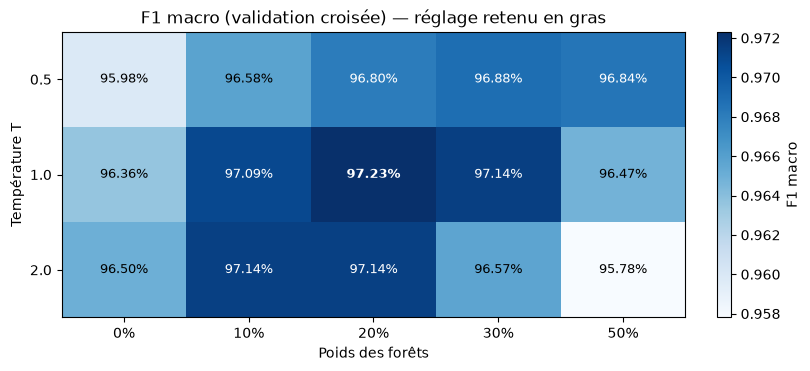

In [174]:
temperatures = [0.5, 1.0, 2.0]
poids_forets_testes = [0.0, 0.1, 0.2, 0.3, 0.5]
sensibilite = pd.DataFrame(index=pd.Index(temperatures, name="température T"),
                           columns=pd.Index(poids_forets_testes, name="poids des forêts"), dtype=float)
for temperature in temperatures:
    for poids in poids_forets_testes:
        reglages = {**REGLAGES_FINAUX, "temperature": temperature, "poids_forets": poids}
        score = combiner_cv(scores_svm_finaux, scores_cv["Random Forest + Extra Trees"], **reglages)
        sensibilite.loc[temperature, poids] = mesurer("combinaison", "", score)["f1_macro_cv"]

fig, ax = plt.subplots(figsize=(8, 3.6), layout="constrained")
image = ax.imshow(sensibilite.to_numpy(), cmap="Blues", aspect="auto")
ax.set_xticks(range(len(poids_forets_testes)), [f"{p:.0%}" for p in poids_forets_testes])
ax.set_yticks(range(len(temperatures)), temperatures)
for i in range(len(temperatures)):
    for j in range(len(poids_forets_testes)):
        valeur = sensibilite.iloc[i, j]
        ax.text(j, i, f"{valeur:.2%}", ha="center", va="center", fontsize=9,
                fontweight="bold" if (temperatures[i], poids_forets_testes[j]) == (1.0, 0.2) else "normal",
                color="white" if valeur > sensibilite.to_numpy().mean() else "black")
ax.set(xlabel="Poids des forêts", ylabel="Température T", title="F1 macro (validation croisée) — réglage retenu en gras")
fig.colorbar(image, ax=ax, label="F1 macro")
fig.savefig(DOSSIER_FIGURES / "06_sensibilite_combinaison.png", dpi=180)
plt.show()

**Constat :** le réglage retenu ($T = 1$, 20 % pour les forêts) obtient le meilleur F1 macro de la grille (**97,23 %**). Ses quatre voisins directs donnent de 96,8 % à 97,1 % : il se situe donc sur un **plateau**, et non sur un pic isolé. Le score ne baisse nettement qu'aux extrêmes : sans les forêts (96,0 % à 96,5 %) ou avec un poids de 50 % (95,8 % à 96,8 %). Cette grille est calculée sur les mêmes prédictions hors échantillon que le tableau précédent : elle situe le réglage, mais ne constitue pas une nouvelle validation.

### 6.8. Comparaison de tous les modèles

Le tableau et le graphique reprennent le meilleur réglage de chaque entraînement, ainsi que les étapes de la combinaison. Les barres d'erreur représentent l'écart-type entre les 3 plis : un écart plus petit que ces barres n'est pas significatif.

,representation,reglage,accuracy_cv,std_accuracy_cv,f1_macro_cv,std_f1_macro_cv,duree_s,avertissements_convergence
Modèle final (… + correction des fréquences),combinaison,"temperature = 1.0, poids_forets = 0.2, alpha =...",97.48%,0.19%,97.23%,0.25%,NaN,0
… + règle du navigateur,combinaison,"temperature = 1.0, poids_forets = 0.2, alpha =...",97.18%,0.11%,96.32%,0.08%,NaN,0
7 SVM + forêts (moyenne géométrique),combinaison,"temperature = 1.0, poids_forets = 0.2, alpha =...",97.06%,0.05%,96.15%,0.21%,NaN,0
1 SVM + forêts (moyenne arithmétique),combinaison,"temperature = 0.2, poids_forets = 0.4, geometr...",96.11%,0.37%,95.04%,0.28%,NaN,0
Moyenne géométrique des 7 SVM seuls,combinaison,"temperature = 1.0, poids_forets = 0.0, alpha =...",96.22%,0.25%,94.47%,0.53%,NaN,0
"SVM TF-IDF avec temps, sans IDF",avec_temps,C = 10,95.11%,0.69%,93.64%,0.84%,80,0
"SVM augmenté (8 extraits, tirage 0)",avec_temps,C = 10,95.46%,0.55%,93.54%,0.54%,128,0
Extra Trees,616 variables,"max_features = 0,15",94.01%,0.35%,93.36%,0.13%,36,0
Random Forest + Extra Trees,616 variables,moyenne des probabilités,94.12%,0.51%,93.29%,0.17%,NaN,0
"SVM augmenté (8 extraits, tirage 1000)",avec_temps,C = 10,95.23%,0.47%,93.26%,0.62%,134,0


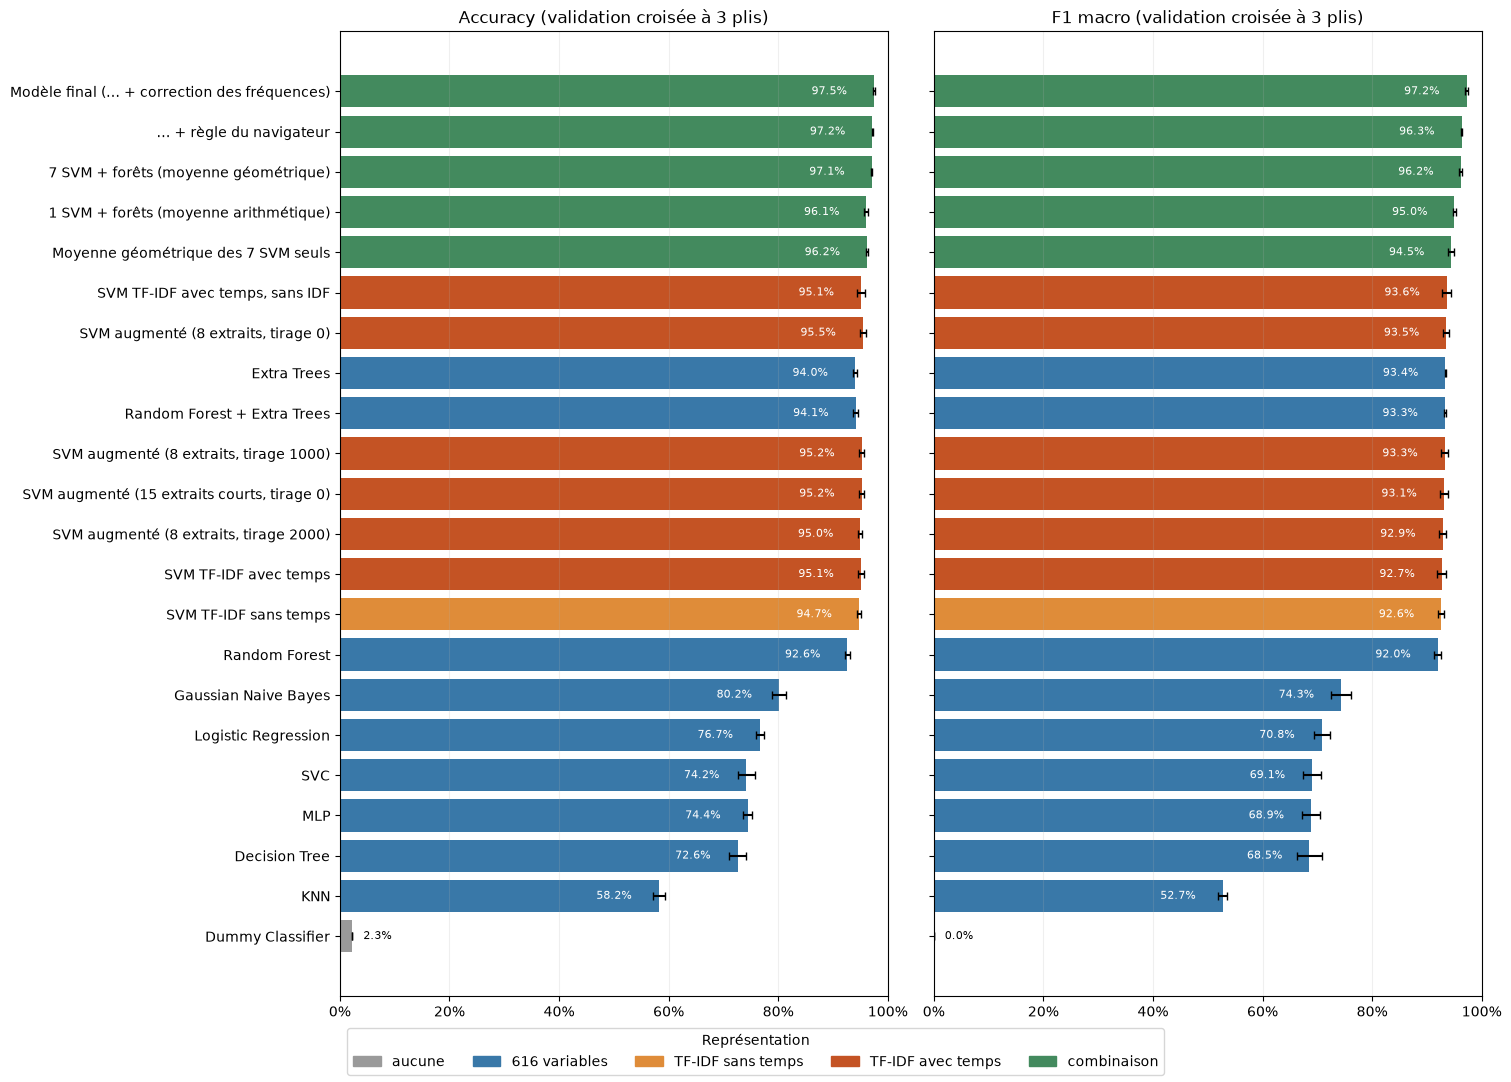

In [175]:
synthese = pd.DataFrame(resultats_cv).T.sort_values("f1_macro_cv", ascending=False)
display(synthese[["representation", "reglage", "accuracy_cv", "std_accuracy_cv", "f1_macro_cv", "std_f1_macro_cv",
                  "duree_s", "avertissements_convergence"]].pipe(formater, FORMAT_RESULTATS))

couleurs = {"aucune": "#9a9a9a", "616 variables": "#3978a8", "sans_temps": "#df8c39", "avec_temps": "#c45324",
            "combinaison": "#438a5e"}
a_tracer = synthese.iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(15, 0.42 * len(a_tracer) + 1.5), sharey=True, layout="constrained")
for ax, metrique, titre in zip(axes, ["accuracy", "f1_macro"], ["Accuracy", "F1 macro"]):
    valeurs = a_tracer[f"{metrique}_cv"].astype(float)
    ax.barh(a_tracer.index, valeurs, xerr=a_tracer[f"std_{metrique}_cv"].astype(float),
            color=a_tracer["representation"].map(couleurs).tolist(), capsize=3)
    for position, valeur in enumerate(valeurs):
        dans_barre = valeur > 0.5
        ax.text(valeur - 0.05 if dans_barre else valeur + 0.02, position, f"{valeur:.1%}", va="center",
                ha="right" if dans_barre else "left", fontsize=8, color="white" if dans_barre else "black")
    ax.set(xlim=(0, 1), title=f"{titre} (validation croisée à 3 plis)")
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis="x", alpha=0.2)
legende = [plt.Rectangle((0, 0), 1, 1, color=c) for c in couleurs.values()]
fig.legend(legende, ["aucune", "616 variables", "TF-IDF sans temps", "TF-IDF avec temps", "combinaison"],
           loc="outside lower center", ncol=5, title="Représentation")
fig.savefig(DOSSIER_FIGURES / "07_comparaison_modeles_cv.png", dpi=180)
plt.show()

In [176]:
synthese.to_csv(DOSSIER_RESULTATS / "comparaison_modeles_cv.csv", encoding="utf-8-sig")
pd.DataFrame(details_reglages).to_csv(DOSSIER_RESULTATS / "reglages_testes_cv.csv", index=False, encoding="utf-8-sig")
with open(DOSSIER_RESULTATS / "protocole.json", "w", encoding="utf-8") as fichier:
    json.dump({"graine": GRAINE, "sessions_apprentissage": int(len(y_app)), "sessions_validation": int(len(y_val)),
               "plis": len(plis), "critere_de_choix": "f1_macro",
               "svm_finaux": [f"{nom} [{reglage}]" for nom, reglage, _ in SVM_FINAUX],
               "reglages_combinaison": REGLAGES_FINAUX}, fichier, ensure_ascii=False, indent=2)
print("Résultats enregistrés dans", DOSSIER_RESULTATS)

Résultats enregistrés dans resultats\rendu_final


**Résultats observés :**

- **Sur le tableau de variables, seuls les ensembles d'arbres dépassent 90 %.** Les Extra Trees (93,4 % de F1 macro) et le Random Forest (92,0 %) devancent de loin le Gaussian Naive Bayes (74,3 %), la Logistic Regression (70,8 %), puis le SVC, le MLP et le Decision Tree (68,6 % à 69,1 %). Le KNN ferme la marche (52,7 %).
- **Sur les documents TF-IDF, un simple SVM linéaire fait aussi bien que les forêts** : de 92,6 % à 93,6 % de F1 macro selon la variante, avec une accuracy un peu supérieure (94,7 % à 95,5 %).
- **Aucun modèle seul ne dépasse 93,6 % de F1 macro**, et les meilleurs sont séparés par moins d'un point, soit de l'ordre de l'écart-type entre plis.
- **La combinaison change d'échelle** : **97,5 %** d'accuracy et **97,2 %** de F1 macro, soit 3,6 points de F1 macro de plus que le meilleur modèle seul. Ce gain dépasse largement l'écart-type entre plis (0,25 point). Il vient de la complémentarité des deux représentations (6.7).
- **Coût.** Les SVM augmentés sont les plus longs à évaluer (de 2 à 5 minutes chacun pour les 3 plis). Les entraînements de la partie 6 totalisent environ 26 minutes, sans aucun avertissement de non-convergence.

Le modèle final est maintenant évalué sur les 656 sessions réservées, qui n'ont servi à aucun choix (partie 7).

## 7. Évaluation de votre solution

### 7.1. Ajustement du modèle final sur l'apprentissage

Le modèle final est maintenant entraîné sur les **80 % d'apprentissage**, puis évalué sur les **20 % réservés**, qui n'ont servi à aucun choix de la partie 6. La classe `ModeleFinal` regroupe l'ensemble du modèle :

1. elle ajuste le tableau de variables, puis le Random Forest et les Extra Trees ;
2. elle ajuste les 7 SVM, dont les SVM augmentés sur les sessions d'entraînement et leurs extraits ;
3. elle combine leurs scores comme en 6.7.

**Gestion de la mémoire.** Une forêt ajustée occupe environ 2 Go, et un SVM environ 200 Mo. La classe calcule donc les scores des ensembles à prédire **pendant** l'ajustement, puis libère chaque modèle. Elle ne garde que les importances des variables des forêts et le premier SVM, utiles pour l'interprétation (partie 8). Pour cette raison, les ensembles à prédire sont donnés dès l'appel à `ajuster`.

In [177]:
def ajuster_svm_et_predire(spec, documents_entrainement, etiquettes, documents_a_predire, garder_modele):
    """Ajuste un SVM du modèle final et renvoie ses scores sur chaque ensemble à prédire."""
    X, y_svm = documents_entrainement, list(etiquettes)
    if spec["augmentation"] is not None:
        graine, options = spec["augmentation"]
        X, y_svm = augmenter(X, y_svm, np.random.default_rng(graine), **options)
    with warnings.catch_warnings(record=True) as avertissements:
        warnings.simplefilter("always", ConvergenceWarning)
        modele = creer_svm_tfidf(C=spec["C"], use_idf=spec["use_idf"]).fit(X, y_svm)
    assert list(modele.classes_) == list(classes)
    scores = {nom: modele.decision_function(docs) for nom, docs in documents_a_predire.items()}
    n_avertissements = sum(issubclass(a.category, ConvergenceWarning) for a in avertissements)
    return scores, (modele if garder_modele else None), n_avertissements


class ModeleFinal:
    """7 SVM TF-IDF + Random Forest et Extra Trees, combinés par moyenne géométrique, règle du navigateur et correction des fréquences."""

    def __init__(self, svms=SVM_FINAUX, reglages=REGLAGES_FINAUX, n_jobs=N_PROCESSUS):
        self.svms, self.reglages, self.n_jobs = svms, reglages, n_jobs

    def ajuster(self, donnees, a_predire):
        """`donnees` : ensemble d'entraînement ; `a_predire` : {nom: ensemble} dont on calcule les scores."""
        debut = time.perf_counter()
        etiquettes = np.asarray(donnees["y"])
        self.composants_ = {nom: {} for nom in a_predire}
        self.navigateurs_ = {nom: np.asarray(d["navigateur"]) for nom, d in a_predire.items()}

        # Forêts : tableau de variables appris sur l'entraînement, puis RF et ET ajustés l'un après l'autre.
        self.tableau_ = TableauVariables().fit(donnees["variables"])
        X_entrainement = self.tableau_.transform(donnees["variables"])
        X_a_predire = {nom: self.tableau_.transform(d["variables"]) for nom, d in a_predire.items()}
        probabilites, importances = {nom: [] for nom in a_predire}, []
        for foret in [
            RandomForestClassifier(n_estimators=500, class_weight="balanced", max_features="sqrt",
                                   min_samples_leaf=1, n_jobs=-1, random_state=0),
            ExtraTreesClassifier(n_estimators=500, class_weight="balanced", max_features=0.15,
                                 min_samples_leaf=2, n_jobs=-1, random_state=0),
        ]:
            foret.fit(X_entrainement, etiquettes)
            assert list(foret.classes_) == list(classes)
            for nom, X in X_a_predire.items():
                probabilites[nom].append(foret.predict_proba(X))
            importances.append(foret.feature_importances_)
            del foret  # libère environ 2 Go avant d'ajuster la forêt suivante
        for nom in a_predire:
            self.composants_[nom]["Random Forest + Extra Trees"] = np.mean(probabilites[nom], axis=0)
        self.importances_ = pd.Series(np.mean(importances, axis=0), index=self.tableau_.colonnes_)
        print(f"Forêts ajustées ({time.perf_counter() - debut:.0f} s)")

        # SVM : chacun est ajusté, prédit les ensembles demandés, puis est libéré (sauf le premier).
        resultats = Parallel(n_jobs=self.n_jobs)(
            delayed(ajuster_svm_et_predire)(
                spec, donnees[self._cle(spec)], etiquettes, {nom: d[self._cle(spec)] for nom, d in a_predire.items()},
                garder_modele=(i == 0))
            for i, (_, _, spec) in enumerate(self.svms))
        self.avertissements_convergence_ = 0
        for (nom_svm, reglage, _), (scores, modele, n_avertissements) in zip(self.svms, resultats):
            for nom in a_predire:
                self.composants_[nom][f"{nom_svm} [{reglage}]"] = scores[nom]
            if modele is not None:
                self.svm_reference_ = modele
            self.avertissements_convergence_ += n_avertissements

        self.navigateur_par_classe_, self.log_frequence_ = navigateur_et_frequences(donnees["navigateur"], etiquettes)
        self.duree_s_ = time.perf_counter() - debut
        print(f"Modèle final ajusté sur {len(etiquettes)} sessions en {self.duree_s_ / 60:.1f} min "
              f"({self.avertissements_convergence_} avertissements de convergence)")
        return self

    @staticmethod
    def _cle(spec):
        return "avec_temps" if spec["avec_temps"] else "sans_temps"

    def noms_svm(self):
        return [f"{nom} [{reglage}]" for nom, reglage, _ in self.svms]

    def scores(self, nom, **reglages):
        """Score combiné de chaque (session, utilisateur) de l'ensemble `nom` ; `reglages` remplace ceux du modèle final."""
        composants = self.composants_[nom]
        masque = self.navigateurs_[nom][:, None] == self.navigateur_par_classe_[None, :]
        return combiner([composants[n] for n in self.noms_svm()], composants["Random Forest + Extra Trees"], masque,
                        self.log_frequence_, **{**self.reglages, **reglages})

    def predire(self, nom):
        return classes[self.scores(nom).argmax(axis=1)]

In [178]:
modele_validation = ModeleFinal().ajuster(donnees_app, {"validation": donnees_val})

Forêts ajustées (38 s)
Modèle final ajusté sur 2620 sessions en 10.4 min (0 avertissements de convergence)


### 7.2. Scores sur la validation réservée

On compare le modèle final à ses composants principaux, ajustés sur le même apprentissage : les forêts seules, le meilleur SVM seul et la moyenne des 7 SVM. Les métriques retenues sont les suivantes :

- **accuracy** : la part de sessions bien attribuées ;
- **F1 macro**, la métrique du classement : la moyenne, sur les utilisateurs, de l'équilibre entre précision et rappel ;
- **F1 pondéré** : le même calcul, chaque utilisateur pesant selon son nombre de sessions ;
- **précision et rappel macro** ;
- **accuracy top-3** : la part de sessions dont le bon utilisateur figure parmi les 3 premiers proposés.

In [179]:
def scores_finis(scores):
    """Remplace -inf (navigateur incompatible) par une valeur très basse, pour les métriques de rang."""
    return np.where(np.isfinite(scores), scores, -1e300)


def metriques(y_vrai, scores):
    predictions = classes[np.asarray(scores).argmax(axis=1)]
    return {
        "accuracy": accuracy_score(y_vrai, predictions),
        "F1 macro": f1_score(y_vrai, predictions, average="macro"),
        "F1 pondéré": f1_score(y_vrai, predictions, average="weighted"),
        "précision macro": precision_score(y_vrai, predictions, average="macro", zero_division=0),
        "rappel macro": recall_score(y_vrai, predictions, average="macro", zero_division=0),
        "accuracy top-3": top_k_accuracy_score(y_vrai, scores_finis(scores), k=3, labels=classes),
        "erreurs": int((predictions != y_vrai).sum()),
    }


composants_validation = modele_validation.composants_["validation"]
candidats_validation = {
    "Random Forest + Extra Trees": composants_validation["Random Forest + Extra Trees"],
    "SVM TF-IDF avec temps": composants_validation[modele_validation.noms_svm()[0]],
    "Moyenne géométrique des 7 SVM seuls": modele_validation.scores("validation", poids_forets=0.0, alpha=0.0,
                                                                     regle_navigateur=False),
    "Modèle final": modele_validation.scores("validation"),
}
evaluation_validation = pd.DataFrame({nom: metriques(y_val, s) for nom, s in candidats_validation.items()}).T
display(evaluation_validation.pipe(formater, {c: "{:.2%}" for c in evaluation_validation.columns if c != "erreurs"}))

# Scores de validation croisée des mêmes modèles (partie 6), pour comparaison
cv_correspondant = pd.DataFrame({
    "Random Forest + Extra Trees": resultats_cv["Random Forest + Extra Trees"],
    "SVM TF-IDF avec temps": mesurer("avec_temps", "C = 10", scores_reglages["SVM TF-IDF avec temps"]["C = 10"]),
    "Moyenne géométrique des 7 SVM seuls": resultats_cv["Moyenne géométrique des 7 SVM seuls"],
    "Modèle final": resultats_cv[NOM_MODELE_FINAL],
}).T
comparaison_cv_validation = pd.DataFrame({
    "F1 macro CV": cv_correspondant["f1_macro_cv"].astype(float),
    "F1 macro validation réservée": evaluation_validation["F1 macro"].astype(float),
    "accuracy CV": cv_correspondant["accuracy_cv"].astype(float),
    "accuracy validation réservée": evaluation_validation["accuracy"].astype(float),
})
print("Validation croisée (partie 6) et validation réservée :")
display(comparaison_cv_validation.pipe(formater, "{:.2%}"))
evaluation_validation.to_csv(DOSSIER_RESULTATS / "evaluation_validation.csv", encoding="utf-8-sig")

,accuracy,F1 macro,F1 pondéré,précision macro,rappel macro,accuracy top-3,erreurs
Random Forest + Extra Trees,94.97%,93.48%,94.34%,94.13%,94.04%,98.32%,33.0
SVM TF-IDF avec temps,94.82%,92.26%,94.12%,93.12%,93.00%,97.71%,34.0
Moyenne géométrique des 7 SVM seuls,95.27%,92.40%,94.46%,92.75%,93.38%,98.17%,31.0
Modèle final,96.80%,95.73%,96.49%,96.25%,96.08%,99.09%,21.0


Validation croisée (partie 6) et validation réservée :


,F1 macro CV,F1 macro validation réservée,accuracy CV,accuracy validation réservée
Random Forest + Extra Trees,93.29%,93.48%,94.12%,94.97%
SVM TF-IDF avec temps,92.73%,92.26%,95.08%,94.82%
Moyenne géométrique des 7 SVM seuls,94.47%,92.40%,96.22%,95.27%
Modèle final,97.23%,95.73%,97.48%,96.80%


**Constat :** sur les 656 sessions réservées, le modèle final obtient **96,8 %** d'accuracy et **95,7 %** de F1 macro, avec **21 erreurs**. Il fait nettement mieux que ses composants : 33 erreurs pour les forêts, 34 pour le SVM de référence et 31 pour la moyenne des 7 SVM. Le bon utilisateur figure parmi ses 3 premières propositions dans **99,1 %** des cas.

**Comparaison avec la validation croisée :**

- Les composants obtiennent des scores proches de ceux de la validation croisée : 93,5 % de F1 macro pour les forêts (93,3 % en CV), 92,3 % pour le SVM (92,7 % en CV).
- Le modèle final perd 0,7 point d'accuracy et 1,5 point de F1 macro (97,2 % en CV). Deux explications se cumulent. D'une part, le F1 macro de validation est bruité : 63 utilisateurs n'y ont qu'une session (6.1), et une seule erreur ramène leur F1 à 0. D'autre part, les réglages de la combinaison ont été fixés sur toutes les sessions étiquetées, ce qui rend le score de validation croisée un peu optimiste (8.6).
- Le gain de la combinaison sur les forêts passe ainsi de 3,9 points de F1 macro en validation croisée à 2,3 points en validation réservée. Il reste le plus important.

Lors de cet ajustement, aucun SVM n'a émis d'avertissement de non-convergence. Ce n'est pas systématique : `LinearSVC` parcourt les sessions dans un ordre aléatoire, et un SVM atteint parfois de justesse la limite d'itérations. C'est le cas dans 5 des 12 ajustements de la section 7.5. Les prédictions n'en sont pas affectées en pratique : une exécution précédente, avec un avertissement ici et en partie 9, donnait les mêmes scores et la même soumission.

### 7.3. Où se trouvent les erreurs ? Selon la longueur des sessions

Une session courte contient peu d'écrans et de configurations caractéristiques. On calcule l'accuracy par tranche de nombre d'actions, pour chaque modèle.

,sessions,Random Forest + Extra Trees,SVM TF-IDF avec temps,Moyenne géométrique des 7 SVM seuls,Modèle final
≤ 50,10,90.0%,90.0%,90.0%,90.0%
51-100,79,93.7%,87.3%,92.4%,96.2%
101-200,121,86.0%,89.3%,88.4%,90.1%
201-500,186,95.2%,96.2%,95.7%,97.3%
501-1000,123,99.2%,99.2%,99.2%,100.0%
> 1000,137,100.0%,98.5%,99.3%,100.0%


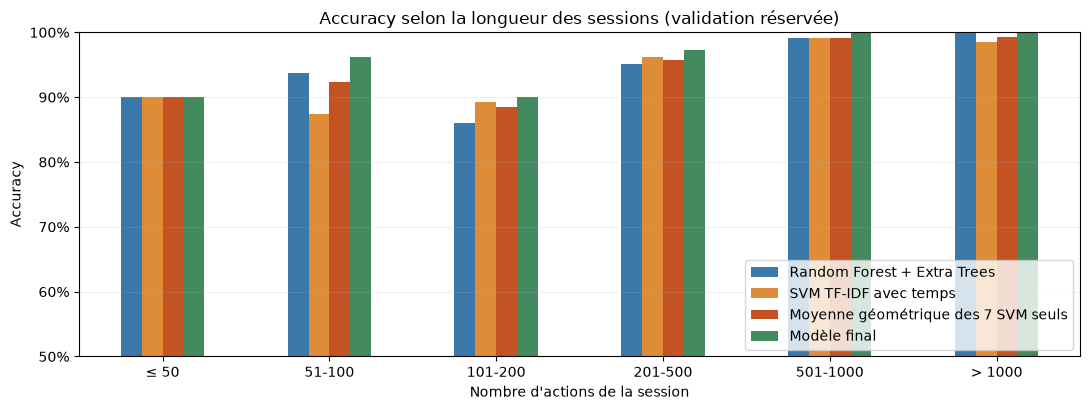

In [180]:
tranches = pd.cut(donnees_val["n_actions"], [0, 50, 100, 200, 500, 1000, np.inf],
                  labels=["≤ 50", "51-100", "101-200", "201-500", "501-1000", "> 1000"])
par_longueur = pd.DataFrame({"sessions": pd.Series(tranches).value_counts().sort_index()})
for nom, s in candidats_validation.items():
    par_longueur[nom] = pd.Series(classes[s.argmax(axis=1)] == y_val).groupby(tranches, observed=False).mean()
display(par_longueur.pipe(formater, {nom: "{:.1%}" for nom in candidats_validation}))

ax = par_longueur[list(candidats_validation)].plot.bar(figsize=(11, 4.2), rot=0,
                                                       color=["#3978a8", "#df8c39", "#c45324", "#438a5e"])
ax.set(ylim=(0.5, 1.0), xlabel="Nombre d'actions de la session", ylabel="Accuracy",
       title="Accuracy selon la longueur des sessions (validation réservée)")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.grid(axis="y", alpha=0.2)
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(DOSSIER_FIGURES / "08_accuracy_selon_longueur.png", dpi=180)
plt.show()

**Constat :** les erreurs se concentrent sur les sessions courtes. Le modèle final ne commet **aucune erreur** au-delà de 500 actions (260 sessions), et 5 erreurs entre 201 et 500 actions. Les **16 autres erreurs** portent sur des sessions de 200 actions ou moins : ces sessions représentent 32 % de la validation, mais 76 % des erreurs. La tranche de 101 à 200 actions en compte à elle seule 12 (90,1 % d'accuracy).

Sur les sessions de 51 à 100 actions, les forêts (93,7 %) font bien mieux que le SVM (87,3 %), et le modèle final (96,2 %) dépasse les deux : c'est un exemple concret de complémentarité. La tranche de 50 actions ou moins ne compte que 10 sessions, et son score (90 %, soit une erreur) est très incertain.

### 7.4. Quels utilisateurs sont mal reconnus, et avec qui sont-ils confondus ?

Avec 247 classes, une matrice de confusion complète serait illisible. On affiche donc :

- les utilisateurs de plus faible F1 ;
- les confusions les plus fréquentes, sous la forme vrai → prédit.

In [181]:
predictions_validation = modele_validation.predire("validation")
rapport = pd.DataFrame(classification_report(y_val, predictions_validation, labels=classes,
                                             target_names=correspondance_classes.tolist(),
                                             output_dict=True, zero_division=0)).T
rapport = rapport.drop(index=["accuracy", "macro avg", "weighted avg"], errors="ignore")
rapport = rapport[rapport["support"] > 0].assign(
    sessions_entrainement=lambda r: r.index.map(sessions["utilisateur"].value_counts()))
print("Les 10 utilisateurs les moins bien reconnus en validation :")
display(rapport.sort_values(["f1-score", "support"]).head(10).round(2))

erreurs = pd.DataFrame({"vrai": correspondance_classes[y_val].to_numpy(),
                        "prédit": correspondance_classes[predictions_validation].to_numpy()})
erreurs = erreurs[erreurs["vrai"] != erreurs["prédit"]]
print(f"{len(erreurs)} erreurs sur {len(y_val)} sessions. Confusions les plus fréquentes :")
display(erreurs.value_counts().head(10).rename("sessions").to_frame())

Les 10 utilisateurs les moins bien reconnus en validation :


,precision,recall,f1-score,support,sessions_entrainement
jew,0.0,0.00,0.00,1.0,4
nkb,0.0,0.00,0.00,1.0,7
ufc,0.0,0.00,0.00,1.0,5
hll,0.0,0.00,0.00,2.0,9
guh,0.5,0.67,0.57,3.0,15
urs,0.5,1.00,0.67,1.0,5
xgb,0.5,1.00,0.67,1.0,7
azx,1.0,0.50,0.67,2.0,10
bos,1.0,0.50,0.67,2.0,9
iyf,1.0,0.50,0.67,2.0,8


21 erreurs sur 656 sessions. Confusions les plus fréquentes :


,,sessions
vrai,prédit,
syt,xgb,1
bos,czi,1
akx,cbo,1
uof,sqb,1
esu,lgd,1
azx,guh,1
slq,urs,1
jew,fgc,1
mmm,byo,1


**Constat :** quatre utilisateurs ont un F1 nul : `jew`, `nkb`, `ufc` et `hll`. Ils ont peu de sessions (de 4 à 9 sessions étiquetées au total, dont 1 ou 2 en validation) : une seule erreur suffit à annuler leur F1, ce qui illustre le bruit du F1 macro de validation (6.1).

Aucune confusion ne se répète : les 21 erreurs correspondent à 21 couples vrai → prédit différents. Le modèle ne confond donc pas systématiquement deux utilisateurs ; ses erreurs sont isolées et portent sur des sessions difficiles, souvent courtes (7.3).

### 7.5. Validation croisée répétée sur toutes les sessions (protocole de nos essais préliminaires)

Lors de nos essais préliminaires, ce même modèle final avait obtenu **98,1 %** d'accuracy et **0,980** de F1 macro. Ici, il obtient 97,2 % de F1 macro en partie 6 et 95,7 % sur la validation réservée. Le modèle n'a pas changé : le notebook produit exactement la soumission de ces essais (partie 10). L'écart vient du **protocole de mesure** :

| | Essais préliminaires | Partie 6 | Partie 7 |
|---|---|---|---|
| Sessions utilisées | toutes (3 276) | apprentissage (2 620) | apprentissage, puis validation réservée |
| Découpage | 4 plis, répété sur 3 découpages | 3 plis, un découpage | 80 / 20 |
| Sessions d'entraînement par modèle | ≈ 2 457 | ≈ 1 747 | 2 620 |
| Sessions évaluées | 3 276, trois fois | 2 620 | 656 |

Avec 247 utilisateurs, chaque session d'entraînement compte. Un utilisateur à 4 sessions en garde 3 pour l'entraînement dans un pli des essais, mais seulement 2 dans un pli de la partie 6.

Cette section mesure donc à nouveau le modèle final **avec le protocole des essais préliminaires** :

- `StratifiedKFold` à 4 plis sur les 3 276 sessions étiquetées, répété avec les graines 0, 1 et 2 ;
- dans chaque pli, le modèle final complet est réajusté (tableau de variables, forêts, 7 SVM, augmentation des seules sessions d'entraînement), puis il prédit les sessions du pli évalué ;
- les scores sont calculés sur l'ensemble des prédictions hors échantillon d'un découpage, puis moyennés sur les 3 découpages.

Cette mesure utilise aussi les sessions de la validation réservée. C'est sans conséquence : tous les choix sont déjà faits, et elle ne sert à en faire aucun.

Le protocole diffère de celui des essais sur deux détails. Ici, le vocabulaire du tableau de variables, les navigateurs et les fréquences des utilisateurs sont appris dans chaque pli, et non une fois pour toutes sur toutes les sessions. Les tirages des extraits de l'augmentation sont aussi différents. Les scores doivent donc être très proches de ceux des essais, sans être identiques à la décimale près.

*Durée : 12 ajustements du modèle final, soit environ 1 h 30.*

In [182]:
GRAINES_DECOUPAGES = [0, 1, 2]
donnees_toutes = sous_ensemble(np.arange(len(sessions)))
y_toutes = donnees_toutes["y"]
debut_repetee = time.perf_counter()

lignes_repetee = []
for graine in GRAINES_DECOUPAGES:
    decoupage = StratifiedKFold(n_splits=4, shuffle=True, random_state=graine)
    scores_hors_echantillon = {}
    for k, (entrainement, evaluation) in enumerate(decoupage.split(np.zeros(len(y_toutes)), y_toutes), start=1):
        print(f"--- Découpage {graine}, pli {k}/4 ({len(entrainement)} sessions d'entraînement)")
        modele_pli = ModeleFinal().ajuster(sous_ensemble(entrainement), {"pli": sous_ensemble(evaluation)})
        composants_pli = modele_pli.composants_["pli"]
        candidats_pli = {
            "Random Forest + Extra Trees": composants_pli["Random Forest + Extra Trees"],
            "SVM TF-IDF avec temps": composants_pli[modele_pli.noms_svm()[0]],
            "Moyenne géométrique des 7 SVM seuls": modele_pli.scores("pli", poids_forets=0.0, alpha=0.0,
                                                                      regle_navigateur=False),
            "Modèle final": modele_pli.scores("pli"),
        }
        for nom, scores_pli in candidats_pli.items():
            scores_hors_echantillon.setdefault(nom, np.empty((len(y_toutes), len(classes))))[evaluation] = scores_pli
        del modele_pli, composants_pli, candidats_pli  # libère la mémoire avant le pli suivant
    for nom, scores_decoupage in scores_hors_echantillon.items():
        predictions = classes[scores_decoupage.argmax(axis=1)]
        lignes_repetee.append({"modèle": nom, "découpage": graine,
                               "accuracy": accuracy_score(y_toutes, predictions),
                               "F1 macro": f1_score(y_toutes, predictions, average="macro"),
                               "erreurs": int((predictions != y_toutes).sum())})

validation_repetee = pd.DataFrame(lignes_repetee)
validation_repetee.to_csv(DOSSIER_RESULTATS / "validation_croisee_repetee.csv", index=False, encoding="utf-8-sig")
print(f"Validation croisée répétée terminée en {(time.perf_counter() - debut_repetee) / 60:.0f} min")

--- Découpage 0, pli 1/4 (2457 sessions d'entraînement)
Forêts ajustées (43 s)
Modèle final ajusté sur 2457 sessions en 10.6 min (0 avertissements de convergence)
--- Découpage 0, pli 2/4 (2457 sessions d'entraînement)
Forêts ajustées (43 s)
Modèle final ajusté sur 2457 sessions en 10.5 min (0 avertissements de convergence)
--- Découpage 0, pli 3/4 (2457 sessions d'entraînement)
Forêts ajustées (44 s)
Modèle final ajusté sur 2457 sessions en 9.2 min (0 avertissements de convergence)
--- Découpage 0, pli 4/4 (2457 sessions d'entraînement)
Forêts ajustées (33 s)
Modèle final ajusté sur 2457 sessions en 8.4 min (1 avertissements de convergence)
--- Découpage 1, pli 1/4 (2457 sessions d'entraînement)
Forêts ajustées (34 s)
Modèle final ajusté sur 2457 sessions en 8.9 min (1 avertissements de convergence)
--- Découpage 1, pli 2/4 (2457 sessions d'entraînement)
Forêts ajustées (35 s)
Modèle final ajusté sur 2457 sessions en 7.3 min (0 avertissements de convergence)
--- Découpage 1, pli 3/4 (

**Résultats.** Le premier tableau donne le F1 macro de chaque découpage, puis les moyennes sur les 3 découpages. La dernière colonne reprend les F1 macro notés lors des essais préliminaires ; la moyenne des 7 SVM seuls n'y avait pas été mesurée. Le second tableau compare les mesures du modèle final selon le protocole.

In [183]:
F1_ESSAIS_PRELIMINAIRES = {"Random Forest + Extra Trees": 0.9506, "SVM TF-IDF avec temps": 0.9503,
                           "Moyenne géométrique des 7 SVM seuls": np.nan, "Modèle final": 0.980}
ordre = list(F1_ESSAIS_PRELIMINAIRES)
tableau_repetee = validation_repetee.pivot(index="modèle", columns="découpage", values="F1 macro").reindex(ordre)
tableau_repetee.columns = [f"F1 macro, découpage {g}" for g in tableau_repetee.columns]
moyennes_repetee = validation_repetee.groupby("modèle")[["accuracy", "F1 macro", "erreurs"]].mean().reindex(ordre)
tableau_repetee["F1 macro moyen"] = moyennes_repetee["F1 macro"]
tableau_repetee["accuracy moyenne"] = moyennes_repetee["accuracy"]
tableau_repetee["erreurs (moyenne sur 3 276)"] = moyennes_repetee["erreurs"]
tableau_repetee["F1 macro des essais préliminaires"] = pd.Series(F1_ESSAIS_PRELIMINAIRES)
display(tableau_repetee.rename_axis(None).pipe(
    formater, {c: "{:.1f}" if c.startswith("erreurs") else "{:.2%}" for c in tableau_repetee.columns}))

protocoles = pd.DataFrame({
    "Partie 6 : 3 plis sur l'apprentissage (≈ 1 747 sessions d'entraînement)": {
        "accuracy": resultats_cv[NOM_MODELE_FINAL]["accuracy_cv"], "F1 macro": resultats_cv[NOM_MODELE_FINAL]["f1_macro_cv"]},
    "Partie 7 : validation réservée (2 620 sessions d'entraînement)": {
        "accuracy": evaluation_validation.loc["Modèle final", "accuracy"],
        "F1 macro": evaluation_validation.loc["Modèle final", "F1 macro"]},
    "Section 7.5 : 4 plis × 3 découpages sur toutes les sessions (≈ 2 457)": {
        "accuracy": moyennes_repetee.loc["Modèle final", "accuracy"],
        "F1 macro": moyennes_repetee.loc["Modèle final", "F1 macro"]},
    "Essais préliminaires : même protocole que la section 7.5": {"accuracy": 0.981, "F1 macro": 0.980},
}).T.astype(float)
print("Le modèle final selon le protocole de mesure :")
display(protocoles.pipe(formater, "{:.2%}"))

,"F1 macro, découpage 0","F1 macro, découpage 1","F1 macro, découpage 2",F1 macro moyen,accuracy moyenne,erreurs (moyenne sur 3 276),F1 macro des essais préliminaires
Random Forest + Extra Trees,95.12%,95.39%,94.77%,95.09%,95.12%,160.0,95.06%
SVM TF-IDF avec temps,95.18%,95.08%,94.83%,95.03%,95.96%,132.3,95.03%
Moyenne géométrique des 7 SVM seuls,96.33%,96.57%,96.26%,96.39%,97.15%,93.3,NaN
Modèle final,97.81%,98.04%,97.68%,97.84%,98.09%,62.7,98.00%


Le modèle final selon le protocole de mesure :


,accuracy,F1 macro
Partie 6 : 3 plis sur l'apprentissage (≈ 1 747 sessions d'entraînement),97.48%,97.23%
Partie 7 : validation réservée (2 620 sessions d'entraînement),96.80%,95.73%
Section 7.5 : 4 plis × 3 découpages sur toutes les sessions (≈ 2 457),98.09%,97.84%
Essais préliminaires : même protocole que la section 7.5,98.10%,98.00%


**Constat :** avec le protocole de nos essais préliminaires, le modèle final obtient **98,1 %** d'accuracy et **97,8 %** de F1 macro en moyenne sur les 3 découpages, soit environ 63 erreurs sur 3 276 sessions. On retrouve les scores des essais (98,1 % et 98,0 %) :

- **Les composants obtiennent les mêmes scores que dans les essais** : 95,1 % de F1 macro pour Random Forest + Extra Trees (95,06 % dans les essais) et 95,0 % pour le SVM TF-IDF avec temps (95,03 %).
- **Le modèle final perd 0,2 point de F1 macro** par rapport aux essais. Sur le découpage 0, il fait 66 erreurs, contre 62 dans les essais. Cet écart correspond aux deux différences de protocole décrites plus haut : vocabulaire, navigateurs et fréquences appris dans chaque pli, et tirages d'augmentation différents.
- **La mesure est stable** : de 97,7 % à 98,0 % de F1 macro selon le découpage.

**L'écart avec les parties 6 et 7 vient donc du protocole, et non du modèle.** Avec ≈ 2 457 sessions d'entraînement au lieu de ≈ 1 747 en partie 6 :

- les composants gagnent environ 2 points de F1 macro : de 93,3 % à 95,1 % pour les forêts, de 92,7 % à 95,0 % pour le SVM de référence, de 94,5 % à 96,4 % pour la moyenne des 7 SVM ;
- le modèle final ne gagne que 0,6 point (de 97,2 % à 97,8 %). La combinaison compense déjà une partie du manque d'exemples de chaque composant.

La hiérarchie est la même dans les trois protocoles : le modèle final, puis la moyenne des 7 SVM, puis les composants seuls.

**Quelle mesure retenir ?**

- **La section 7.5 donne la mesure la plus précise** : chaque session est évaluée trois fois, et les modèles apprennent sur plus de sessions. Comme la partie 6, elle reste un peu optimiste, car les réglages de la combinaison ont été fixés sur ces mêmes sessions lors des essais.
- **La partie 7 donne la mesure la plus prudente** (95,7 % de F1 macro) : en dehors de ces réglages (8.6), ses sessions n'ont servi à aucun choix.
- **Le modèle soumis est ajusté sur les 3 276 sessions**, soit plus que dans un pli de cette section. Son score Kaggle (0,991) prolonge la tendance observée ici : plus il y a d'exemples par utilisateur, moins il y a d'erreurs. Ce score reste bruité, car il ne porte que sur une partie des 324 sessions du test.

## 8. Discussion au sujet de vos résultats

### 8.1. Quel degré de confiance accorder à une prédiction ?

On convertit le score combiné en probabilité par un softmax. Le score est une log-probabilité, à une constante près. On regarde ensuite si la confiance annoncée correspond à la réussite réelle : pour chaque tranche de confiance, l'accuracy observée en validation.

,sessions,accuracy
confiance,,
"(-0.001, 0.2]",573,96.3%
"(0.2, 0.4]",77,100.0%
"(0.4, 0.6]",1,100.0%
"(0.6, 0.8]",0,NaN
"(0.8, 1.0]",5,100.0%


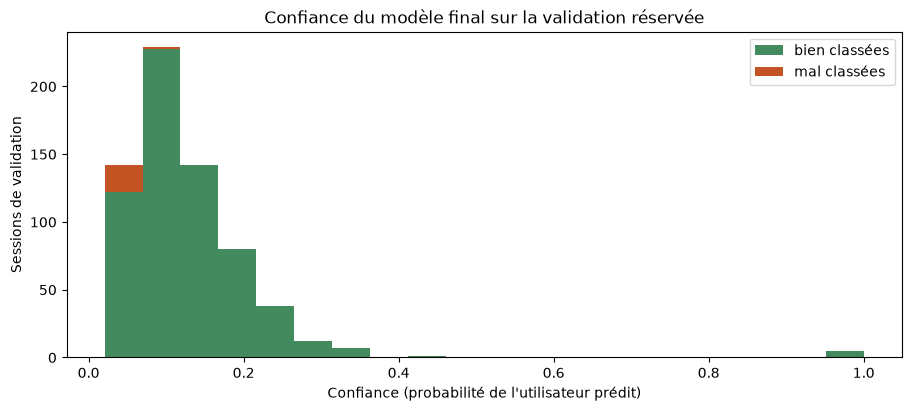

Confiance médiane : 0.11 (bien classées), 0.03 (mal classées)


In [184]:
proba_validation = softmax(modele_validation.scores("validation"), 1.0)
confiance_validation = proba_validation.max(axis=1)
bien_classees = classes[proba_validation.argmax(axis=1)] == y_val
tranches_confiance = pd.cut(confiance_validation, [0, 0.2, 0.4, 0.6, 0.8, 1.0], include_lowest=True)
display(pd.DataFrame({
    "sessions": pd.Series(bien_classees).groupby(tranches_confiance, observed=False).size(),
    "accuracy": pd.Series(bien_classees).groupby(tranches_confiance, observed=False).mean(),
}).rename_axis("confiance").pipe(formater, {"accuracy": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
ax.hist([confiance_validation[bien_classees], confiance_validation[~bien_classees]], bins=20, stacked=True,
        color=["#438a5e", "#c45324"], label=["bien classées", "mal classées"])
ax.set(xlabel="Confiance (probabilité de l'utilisateur prédit)", ylabel="Sessions de validation",
       title="Confiance du modèle final sur la validation réservée")
ax.legend()
fig.savefig(DOSSIER_FIGURES / "09_confiance_validation.png", dpi=180)
plt.show()
print(f"Confiance médiane : {np.median(confiance_validation[bien_classees]):.2f} (bien classées), "
      f"{np.median(confiance_validation[~bien_classees]):.2f} (mal classées)")

**Constat :** la « confiance » du modèle final **n'est pas une probabilité calibrée**. 87 % des sessions de validation (573 sur 656) reçoivent une confiance de 0,2 ou moins, et elles sont pourtant bien classées à 96,3 %. Ces valeurs basses viennent de la construction du score : avec $T = 1$, le softmax des scores des SVM répartit la probabilité sur de nombreux utilisateurs, et la moyenne géométrique conserve cet aplatissement. Les 5 sessions de confiance proche de 1 sont celles du navigateur Opera : un seul utilisateur l'utilise, et la règle du navigateur ne laisse qu'un candidat.

La confiance reste utile **pour classer** les sessions : les 21 erreurs ont toutes une confiance de 0,2 ou moins, et leur confiance médiane (0,03) est près de quatre fois plus faible que celle des sessions bien classées (0,11). En pratique, on pourrait faire vérifier en priorité les sessions de plus faible confiance.

### 8.2. Quelles variables sont les prédicteurs les plus forts pour les forêts ?

On utilise l'importance par **diminution d'impureté**, moyennée entre le Random Forest et les Extra Trees : chaque nœud qui utilise une variable crédite celle-ci de l'amélioration de pureté qu'il apporte. On regroupe ensuite les importances par famille.

Cette mesure a une limite connue : elle favorise les variables continues aux nombreuses valeurs, et sous-estime une variable binaire comme le navigateur, utilisée rarement mais tôt dans les arbres.

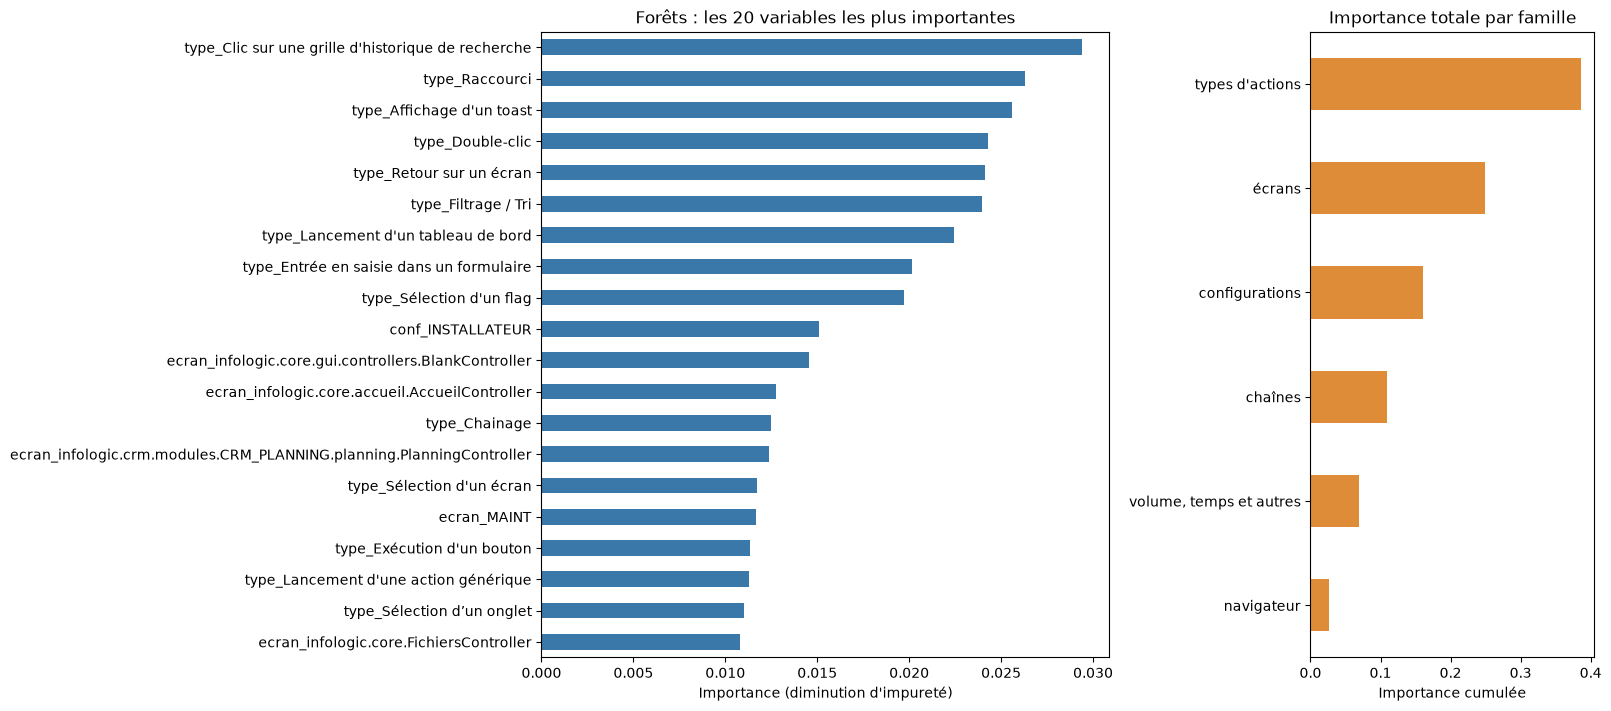

,% de l'importance
types d'actions,38.6
écrans,24.9
configurations,16.1
chaînes,10.9
"volume, temps et autres",6.9
navigateur,2.7


In [185]:
importances = modele_validation.importances_.sort_values(ascending=False)
par_famille = importances.groupby(importances.index.map(famille_variable)).sum().sort_values()
fig, axes = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={"width_ratios": [2, 1]}, layout="constrained")
importances.head(20).sort_values().plot.barh(ax=axes[0], color="#3978a8")
axes[0].set(title="Forêts : les 20 variables les plus importantes", xlabel="Importance (diminution d'impureté)")
par_famille.plot.barh(ax=axes[1], color="#df8c39")
axes[1].set(title="Importance totale par famille", xlabel="Importance cumulée")
fig.savefig(DOSSIER_FIGURES / "10_importances_forets.png", dpi=180)
plt.show()
display((par_famille.sort_values(ascending=False) * 100).round(1).rename("% de l'importance").to_frame())

**Constat :** pour les forêts, les **types d'actions** forment la famille la plus importante : **38,6 %** de l'importance totale, avec seulement 35 colonnes. Suivent les écrans (24,9 %, 303 colonnes), les configurations (16,1 %) et les chaînes (10,9 %).

Les 9 premières variables sont toutes des types d'actions : clic sur une grille d'historique de recherche, raccourci, affichage d'un toast, double-clic, etc. Ce sont des **habitudes d'utilisation** de l'interface, ce qui concorde avec les η² élevés de la section 5.3. Les variables de volume et de temps ne pèsent que 6,9 %, et le navigateur 2,7 %. Ce faible score du navigateur tient en partie à la limite de la mesure, qui sous-estime une variable binaire ; dans le modèle final, le navigateur sert de toute façon de règle (6.7).

### 8.3. Quels mots caractérisent un utilisateur pour le SVM ?

Le SVM linéaire attribue un coefficient à chaque mot et à chaque utilisateur. Les coefficients les plus élevés désignent les mots qui « votent » le plus pour cet utilisateur. On les affiche pour deux utilisateurs souvent confondus dans nos essais, `skm` et `slq`, à défaut les deux plus représentés. Le SVM utilisé est celui des documents avec temps et `C = 10`, ajusté sur l'apprentissage.

In [186]:
svm_reference = modele_validation.svm_reference_
vocabulaire = svm_reference[0].get_feature_names_out()
coefficients = svm_reference[-1].coef_
utilisateurs_exemples = [u for u in ["skm", "slq"] if u in set(correspondance_classes)]
utilisateurs_exemples = utilisateurs_exemples or sessions["utilisateur"].value_counts().index[:2].tolist()
code_utilisateur = {u: k for k, u in correspondance_classes.items()}
for utilisateur in utilisateurs_exemples:
    k = code_utilisateur[utilisateur]
    meilleurs = np.argsort(coefficients[k])[::-1][:8]
    print(f"--- Mots qui votent le plus pour {utilisateur}")
    for j in meilleurs:
        print(f"  {coefficients[k, j]:5.2f}  {vocabulaire[j][:110]}")
plus_forts = np.argsort(np.abs(coefficients).max(axis=0))[::-1][:1000]
print(f"\nTaille du vocabulaire : {len(vocabulaire):,} mots")
print("Sortes de mots parmi les 1 000 coefficients les plus forts (tous utilisateurs) :")
display(pd.Series(Counter(sorte_mot(vocabulaire[j]) for j in plus_forts)).sort_values(ascending=False)
        .rename("mots").to_frame())

--- Mots qui votent le plus pour skm
   1.77  Raccourci1 >> Raccourci dans l'édition de table1
   1.67  Action de table1 >> Lancement d'une action générique
   1.55  CONF=ADM_055
   1.45  Raccourci(fr.infologic.compta.client.modules.saisiecrit.SaisiEcritForm)
   1.35  Raccourci(fr.infologic.compta.client.modules.saisiecrit.SaisiEcritForm) >> Saisie dans un champ
   1.28  TEMPS >> Raccourci(fr.infologic.compta.client.modules.saisiecrit.SaisiEcritForm)
   1.06  Création d'un écran(infologic.core.gui.controllers.nested.InputFormNestedWindow)<ADM_055>
   1.00  Fermeture d'une dialogue1 >> Lancement d'une action générique
--- Mots qui votent le plus pour slq
   1.16  Saisie dans un champ(infologic.infoc.statmodif.fichierbase.StatFBController)1 >> Saisie dans un champ1
   1.16  Exécution d'un bouton(fr.infologic.global.client.modules.pdfviewer.PdfViewerForm) >> TEMPS
   1.06  Affichage d'une dialogue(fr.infologic.core.client.modules.menu.homescreen.HomeViewController) >> Exécution d'u
   0.9

,mots
paire d'actions,527
action complète,177
paire contenant TEMPS,164
composant CONF,46
composant ECRAN,46
composant CHAINE,20
composant TYPE,17
composant NAV,3


**Constat :** les mots qui votent le plus pour un utilisateur décrivent son activité :

- pour `skm` : la saisie d'écritures comptables (`SaisiEcritForm`), la configuration `ADM_055` et des actions portant le suffixe `1`, en accord avec la part élevée de ce suffixe observée en 5.2 ;
- pour `slq` : un écran de statistiques (`StatFBController`), la visionneuse PDF, l'écran d'accueil, la fiche fournisseur et la configuration `ChantierInstallation`.

Parmi les 1 000 coefficients les plus forts, tous utilisateurs confondus, **53 % portent sur des paires d'actions**, 18 % sur des actions complètes et 16 % sur des paires contenant `TEMPS`. Les composants séparés n'en représentent que 13 %. Le SVM s'appuie donc surtout sur ce que le tableau de variables ne voit pas : les combinaisons exactes, l'ordre des actions et le rythme. C'est ce qui rend les deux représentations complémentaires.

### 8.4. Pourquoi cette prédiction ? Explication d'une session particulière

Pour un SVM linéaire, le score d'un utilisateur est la somme, sur les mots de la session, de la valeur TF-IDF du mot multipliée par son coefficient (plus une constante). On peut donc lire **la contribution de chaque mot**. On l'affiche pour une session de validation de l'utilisateur étudié ci-dessus, en comparant l'utilisateur prédit et le deuxième candidat du modèle final.

In [187]:
code_etudie = code_utilisateur[utilisateurs_exemples[0]]
position = int(np.flatnonzero(y_val == code_etudie)[0])
scores_session = modele_validation.scores("validation")[position]
premier, second = np.argsort(scores_session)[::-1][:2]
print(f"Session de validation de {correspondance_classes[code_etudie]} ({donnees_val['n_actions'][position]} actions) : "
      f"prédit {correspondance_classes[premier]} (confiance {softmax(scores_session[None, :], 1.0)[0, premier]:.0%}), "
      f"deuxième candidat {correspondance_classes[second]}")
vecteur = svm_reference[0].transform([donnees_val["avec_temps"][position]]).tocsr()
for candidat in [premier, second]:
    contributions = vecteur.data * coefficients[candidat, vecteur.indices]  # valeur TF-IDF × coefficient
    print(f"--- Mots qui pèsent le plus en faveur de {correspondance_classes[candidat]} "
          f"(somme des contributions : {contributions.sum():+.2f})")
    for i in np.argsort(contributions)[::-1][:6]:
        print(f"  {contributions[i]:+.3f}  {vocabulaire[vecteur.indices[i]][:110]}")

Session de validation de skm (279 actions) : prédit skm (confiance 5%), deuxième candidat flj
--- Mots qui pèsent le plus en faveur de skm (somme des contributions : +0.65)
  +0.108  CONF=ADM_055
  +0.105  Raccourci >> Saisie dans un champ
  +0.084  Saisie dans un champ >> Raccourci
  +0.056  ECRAN=fr.infologic.compta.client.modules.reglement.PaiementForm
  +0.056  Saisie dans un champ(fr.infologic.compta.client.modules.lettrepaiement.LettreVirementForm)
  +0.056  ECRAN=fr.infologic.compta.client.modules.remise.transfert.virement.TransfertVirSepaForm
--- Mots qui pèsent le plus en faveur de flj (somme des contributions : -0.06)
  +0.070  ECRAN=fr.infologic.achats.client.modules.ficheclifour.FicheFournisseurForm
  +0.068  Raccourci >> Saisie dans un champ
  +0.065  Saisie dans un champ >> Saisie dans un champ
  +0.057  Saisie dans un champ >> Raccourci
  +0.037  Exécution d'un bouton(fr.infologic.global.client.modules.pdfviewer.PdfViewerForm)
  +0.037  Raccourci(fr.infologic.achats.clie

**Constat :** cette session de 279 actions de `skm` est bien attribuée, avec une confiance de 5 % ; `flj` est le deuxième candidat. Dans le SVM, l'écart est pourtant net : la somme des contributions des mots vaut +0,65 pour `skm`, contre −0,06 pour `flj`.

Certains mots comptent pour les deux utilisateurs, comme les enchaînements entre raccourci et saisie dans un champ : c'est une habitude commune. La différence vient des mots propres à `skm` : la configuration `ADM_055` et des écrans de règlement et de virement (`PaiementForm`, `LettreVirementForm`, `TransfertVirSepaForm`). La prédiction repose donc sur des écrans métier précis. La faible confiance affichée confirme qu'elle n'est pas calibrée (8.1).

### 8.5. Redondance entre variables

La section 5.4 montre plusieurs variables de volume et de temps fortement corrélées entre elles : ρ = 0,998 entre les actions par minute et la moyenne par fenêtre de 5 s, et ρ = 0,96 entre le nombre d'actions et la durée. Pour les forêts, cette redondance n'est pas gênante pour la prédiction, mais elle partage l'importance entre variables corrélées. Il faut donc lire les importances de la section 8.2 **par famille** plutôt que variable par variable.

Côté TF-IDF, une action complète, ses composants et les paires qui la contiennent sont aussi redondants. C'est voulu : un composant permet de rapprocher deux actions différentes sur le même écran, et une paire capte l'ordre.

### 8.6. Bilan, limites et pistes écartées

**Bilan :**

- **La représentation compte davantage que le choix du modèle.** Sur le tableau de variables, seuls les ensembles d'arbres dépassent 90 %. Sur les documents TF-IDF, un simple SVM linéaire atteint de 92,6 à 93,6 % de F1 macro.
- **La combinaison est l'étape décisive.** Elle porte le F1 macro de validation croisée de 93,6 % (meilleur modèle seul) à **97,2 %**. Associer les forêts aux SVM, passer à la moyenne géométrique de 7 SVM et corriger les fréquences en apportent l'essentiel.
- **Sur la validation réservée**, le modèle final obtient **96,8 %** d'accuracy et **95,7 %** de F1 macro : 21 erreurs sur 656 sessions, contre 33 pour les forêts seules. Le bon utilisateur figure parmi ses 3 premières propositions dans 99,1 % des cas.
- **Avec le protocole de nos essais préliminaires** (4 plis × 3 découpages sur toutes les sessions, section 7.5), il obtient **98,1 %** d'accuracy et **97,8 %** de F1 macro. Il retrouve ainsi les scores des essais : l'écart avec les parties 6 et 7 vient du nombre de sessions d'entraînement, et non du modèle.
- **Sur le test**, réajusté sur toutes les sessions étiquetées, il obtient **0,991** au classement public Kaggle.

**Limites :**

- **Une validation réservée légèrement optimiste.** Les réglages de la combinaison et le choix des 7 SVM ont été fixés lors d'essais préliminaires sur toutes les sessions étiquetées, y compris celles qui forment ici la validation réservée. L'écart reste faible, car ces réglages sont sur un plateau (section 6.7), mais le score de la partie 7 n'est pas une mesure parfaitement indépendante.
- **Des erreurs concentrées sur les sessions courtes et les petits utilisateurs.** Une session de quelques dizaines d'actions contient trop peu d'écrans caractéristiques. Un utilisateur à 4 sessions n'offre que 3 exemples d'apprentissage.
- **Un modèle coûteux et complexe.** Il compte 7 SVM et 1 000 arbres. Un ajustement demande de 4 à 16 minutes selon la charge de la machine, et plusieurs gigaoctets de mémoire. Le notebook complet s'exécute en environ deux heures et demie, dont une heure et demie pour la section 7.5. Le gain des derniers ingrédients est de quelques dixièmes de point.
- **Un score public Kaggle bruité.** Il porte sur une partie seulement des 324 sessions du test : une erreur y pèse lourd. Nos choix ont donc été faits sur la validation croisée, et non sur le score public, d'autant que le nombre de soumissions par jour est limité.

**Pistes testées lors des essais préliminaires et écartées** (gain nul ou instable sur 3 découpages) :

- *Boosting* (XGBoost, AdaBoost, HistGradientBoosting) : nettement moins bon que les forêts avec 247 classes et peu d'exemples par classe, et bien plus lent.
- Paires et triplets de **types** d'actions dans le tableau de variables, ou triplets d'actions dans les documents : ils diluent le signal.
- Logistic Regression, KNN et Naive Bayes sur la TF-IDF : moins bons que le SVM linéaire.
- Méta-modèle (*stacking*) pour choisir session par session le modèle à croire : il sur-apprend, car il n'y a pas assez d'erreurs pour apprendre.
- Sélection des mots par χ² : elle supprime des mots rares, qui sont justement des signatures.
- Pondérations alternatives (BM25, racine carrée, norme L1) et MLP sur la TF-IDF.

## 9. Évaluation sur l'ensemble de données de test

Le modèle final est réajusté sur **toutes les sessions étiquetées**, apprentissage et validation réservée, avec exactement les mêmes réglages. Plus d'exemples par utilisateur améliore surtout les petits utilisateurs. On l'applique ensuite aux 324 sessions du test, dont les variables et les documents ont été construits comme ceux de l'entraînement (sections 4.1 à 4.5).

On libère d'abord le modèle de la partie 7 pour récupérer de la mémoire.

In [188]:
del modele_validation, svm_reference
donnees_toutes = sous_ensemble(np.arange(len(sessions)))
donnees_test = {
    "variables": sessions_test[COLONNES_ENTREE],
    "sans_temps": documents_test[False],
    "avec_temps": documents_test[True],
    "navigateur": sessions_test["navigateur"].to_numpy(),
}
modele_final = ModeleFinal().ajuster(donnees_toutes, {"test": donnees_test})
score_test = modele_final.scores("test")
codes_predits = score_test.argmax(axis=1)
utilisateurs_predits = correspondance_classes[codes_predits].to_numpy()
confiance_test = softmax(score_test, 1.0).max(axis=1)

Forêts ajustées (32 s)
Modèle final ajusté sur 3276 sessions en 15.9 min (0 avertissements de convergence)


**Contrôles des prédictions du test.** On vérifie les points suivants :

- la cohérence avec la règle du navigateur ;
- le nombre d'utilisateurs différents prédits ;
- la distribution de la confiance ;
- la proximité entre la répartition des prédictions et celle de l'entraînement.

Sessions dont l'utilisateur prédit utilise le même navigateur : 100.0%
Utilisateurs différents prédits : 227 sur 247
Confiance médiane : 0.13 ; sessions avec une confiance < 0,2 : 272
Corrélation entre les deux répartitions : 0.92


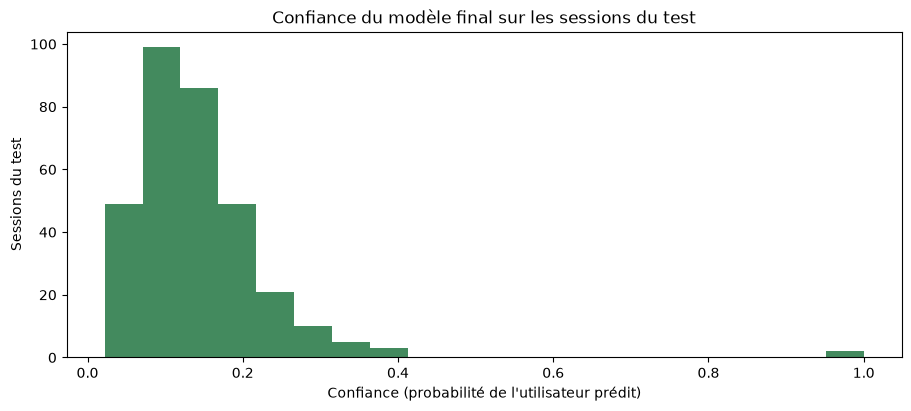

In [189]:
navigateur_predit = pd.Series(modele_final.navigateur_par_classe_[codes_predits])
print(f"Sessions dont l'utilisateur prédit utilise le même navigateur : "
      f"{(navigateur_predit.to_numpy() == sessions_test['navigateur'].to_numpy()).mean():.1%}")
print(f"Utilisateurs différents prédits : {len(set(utilisateurs_predits))} sur {len(classes)}")
print(f"Confiance médiane : {np.median(confiance_test):.2f} ; sessions avec une confiance < 0,2 : {(confiance_test < 0.2).sum()}")

frequences = pd.DataFrame({
    "part dans l'entraînement": sessions["utilisateur"].value_counts(normalize=True),
    "part dans les prédictions du test": pd.Series(utilisateurs_predits).value_counts(normalize=True),
}).fillna(0)
print(f"Corrélation entre les deux répartitions : {frequences.corr().iloc[0, 1]:.2f}")

fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
ax.hist(confiance_test, bins=20, color="#438a5e")
ax.set(xlabel="Confiance (probabilité de l'utilisateur prédit)", ylabel="Sessions du test",
       title="Confiance du modèle final sur les sessions du test")
fig.savefig(DOSSIER_FIGURES / "11_confiance_test.png", dpi=180)
plt.show()

**Constat :**

- Toutes les prédictions respectent la règle du navigateur (100 %).
- **227 utilisateurs différents** sont prédits sur 247. Avec 324 sessions de test, soit 1,3 par utilisateur en moyenne, il est plausible que certains utilisateurs n'aient aucune session dans le test.
- La confiance médiane est de 0,13, et 272 sessions (84 %) ont une confiance inférieure à 0,2, comme en validation (87 %, médiane de 0,11). Le test ne paraît donc pas plus difficile que la validation.
- La répartition des prédictions par utilisateur suit celle de l'entraînement (corrélation de 0,92) : le modèle ne concentre pas ses prédictions sur quelques gros utilisateurs.

Aucun SVM n'a émis d'avertissement de non-convergence pendant l'ajustement (voir la remarque de la partie 7). Les prédictions sont identiques à celles de la soumission notée 0,991 sur Kaggle (partie 10).

## 10. Soumission à la compétition Kaggle

Le fichier suit le format de `sample_submission.csv` : `RowId`, de 1 à 324 dans l'ordre du fichier de test, et `prediction`, l'identifiant de l'utilisateur décodé à partir de son code (section 4.2). Il est écrit à la racine du projet sous le nom `submission.csv`.

Ce fichier est celui que nous avons soumis sur Kaggle (score public **0,991**).

In [190]:
soumission = pd.DataFrame({"RowId": np.arange(1, len(sessions_test) + 1), "prediction": utilisateurs_predits})
modele_soumission = pd.read_csv(trouver_fichier("sample_submission"))
assert list(soumission.columns) == list(modele_soumission.columns)
assert soumission["RowId"].tolist() == modele_soumission["RowId"].tolist()
assert soumission["prediction"].isin(correspondance_classes).all()
soumission.to_csv("submission.csv", index=False)
print(f"submission.csv écrit : {len(soumission)} lignes, {soumission['prediction'].nunique()} utilisateurs différents")
display(soumission.head())




submission.csv écrit : 324 lignes, 227 utilisateurs différents


,RowId,prediction
0,1,hzx
1,2,prb
2,3,jmq
3,4,psg
4,5,cvw


## Conclusion

**Démarche.** Chaque session a été représentée de deux façons : un tableau de 616 variables (proportions et mesures de rythme), et un document TF-IDF formé des actions, de leurs enchaînements et de leurs composants. Une vingtaine de modèles ont été comparés par validation croisée stratifiée sur 80 % des sessions étiquetées, une cellule par entraînement. Les meilleurs, les forêts et les SVM linéaires, ont ensuite été combinés par une moyenne géométrique de leurs probabilités, avec la règle du navigateur et une correction des fréquences.

**Résultats.**

| Modèle et évaluation | Accuracy | F1 macro |
|---|---|---|
| Meilleur modèle seul, validation croisée | 95,1 % | 93,6 % |
| Modèle final, validation croisée | 97,5 % | 97,2 % |
| Modèle final, validation réservée (656 sessions) | 96,8 % | 95,7 % |
| Modèle final, validation croisée répétée sur toutes les sessions (section 7.5) | 98,1 % | 97,8 % |
| Modèle final, classement public Kaggle | — | 0,991 |

Les écarts entre ces mesures viennent du protocole, et non du modèle. Avec ≈ 1 747 sessions d'entraînement par pli (partie 6), le modèle final obtient 97,2 % de F1 macro ; avec ≈ 2 457 (section 7.5), il obtient 97,8 %, comme lors de nos essais préliminaires. Avec 247 utilisateurs, chaque session d'entraînement compte.

**Enseignements.** Les écrans, configurations et enchaînements exacts identifient un utilisateur bien mieux que des statistiques globales de rythme. Les deux représentations se trompent sur des sessions différentes : c'est leur combinaison qui apporte le gain le plus important.

**Limites.** Les erreurs restantes portent surtout sur les sessions de 200 actions ou moins et sur les utilisateurs qui ont peu de sessions. La validation réservée est un peu optimiste, car les réglages de la combinaison ont été fixés sur toutes les sessions étiquetées. Enfin, le modèle est lourd : 7 SVM et 1 000 arbres, de 4 à 16 minutes par ajustement, et environ deux heures et demie pour exécuter le notebook complet.